# 🎯 CKC Attack Sequence Generation with ReALTabFormer

## Top 25 Features + SecBERT Embeddings → Realistic APT Kill Chain Sequences

This notebook:
1. **Loads the top 25 features** from feature selection (malicious detection + CKC stage classification)
2. **Adds CKC stage, MITRE tactic/technique** columns
3. **Retrains ReALTabFormer** (stratified per source type) on the selected features
4. **Generates synthetic attack sequences** through the Cyber Kill Chain — **all ending with S7**
5. **Decodes embeddings back to human-readable text** via cosine similarity with SecBERT
6. **Saves everything to `D:\PFE_CKC\`**

In [22]:
# ============================================================================
# 🔇 WARNING SUPPRESSION & ENVIRONMENT SETUP
# ============================================================================
import os, sys, warnings

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES', '0')
os.environ['GRPC_VERBOSITY'] = 'ERROR'
os.environ['GLOG_minloglevel'] = '3'
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
os.environ['WANDB_MODE'] = 'disabled'
os.environ['JAX_PLATFORMS'] = ''

warnings.filterwarnings('ignore')
if not sys.warnoptions:
    warnings.simplefilter("ignore")

import logging
logging.getLogger().setLevel(logging.ERROR)
for name in ['absl', 'tensorflow', 'transformers', 'realtabformer']:
    logging.getLogger(name).setLevel(logging.ERROR)

try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    tf.autograph.set_verbosity(0)
except ImportError:
    pass

print("✅ All warning suppressions activated")

✅ All warning suppressions activated


In [3]:
# ============================================================================
# 📦 INSTALL & IMPORT DEPENDENCIES
# ============================================================================
import subprocess, sys

def install_package(package):
    try:
        __import__(package.split('[')[0].split('==')[0])
    except ImportError:
        print(f"📦 Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

for pkg in ["realtabformer", "pandas", "numpy", "matplotlib", "seaborn",
            "scikit-learn", "scipy", "tqdm", "plotly", "torch", "transformers",
            "openpyxl", "sentence-transformers"]:
    install_package(pkg)

import json, pickle, re, types, math, shutil
from datetime import datetime
from pathlib import Path
from glob import glob
from collections import Counter, defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import ks_2samp

from tqdm.auto import tqdm
from realtabformer import REaLTabFormer
import torch

try:
    from sentence_transformers import SentenceTransformer
    SECBERT_AVAILABLE = True
except ImportError:
    SECBERT_AVAILABLE = False

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 70)
print("🖥️ SYSTEM INFO")
print(f"   PyTorch: {torch.__version__}  |  Device: {device.upper()}")
if device == "cuda":
    print(f"   GPU: {torch.cuda.get_device_name(0)}  |  Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"   SecBERT: {'✅' if SECBERT_AVAILABLE else '❌'}  |  Seed: {RANDOM_SEED}")
print("=" * 70)

📦 Installing scikit-learn...
📦 Installing sentence-transformers...
🖥️ SYSTEM INFO
   PyTorch: 2.2.1+cu118  |  Device: CUDA
   GPU: NVIDIA GeForce RTX 2060 SUPER  |  Memory: 8.6 GB
   SecBERT: ✅  |  Seed: 42


In [4]:
# ============================================================================
# ⚙️ CONFIGURATION — Paths, Top 25 Features, CKC Patterns
# ============================================================================

PARENT_DIR = r'c:\Users\KassoussiOussama-PFE\Downloads\pfe'
OUTPUT_DIR = r'D:\PFE_CKC'
os.makedirs(OUTPUT_DIR, exist_ok=True)

CONFIG = {
    'data_path': os.path.join(PARENT_DIR, 'malicious_realtabformer_filtered.xlsx'),
    'combined_data_path': os.path.join(PARENT_DIR, 'combined_dataset_final.xlsx'),
    'embeddings_path': os.path.join(PARENT_DIR, 'realtabformer_output', 'secbert_embeddings.pkl'),
    'existing_models_dir': os.path.join(PARENT_DIR, 'realtabformer_output'),
    'checkpoints_dir': os.path.join(OUTPUT_DIR, 'ckc_checkpoints'),
    'model_dir': os.path.join(OUTPUT_DIR, 'ckc_models'),
    'output_dir': OUTPUT_DIR,
    # Training
    'epochs': 150, 'batch_size': 32, 'gradient_accumulation_steps': 4,
    'logging_steps': 100, 'save_steps': 500, 'train_size': 0.95,
    'random_seed': 42,
    # Generation
    'n_sequences': 500, 'oversample_factor': 5,
    'synthetic_ratio': 2.0,
    # SecBERT
    'secbert_model': 'jackaduma/SecBERT',
    'n_pca_dims': 16,
    'device': device,
}

# ── Top 25 DISTINCT Features (from feature_selection_outputs) ──
# Embeddings counted as ONE feature each (expanding to 16 PCA dims internally)
TOP_25_FEATURES = [
    'log_secbert_embedding',                    # 1.  SecBERT log desc embedding (1 feature → 16 PCA dims)
    'decoder_auditd',                           # 2.  Audit daemon decoder flag
    'firedtimes',                               # 3.  Rule fire count
    'location__var_log_audit_audit.log',        # 4.  Audit log location flag
    'srcip_is_private',                         # 5.  Source IP is RFC1918 private
    'decoder_web-accesslog',                    # 6.  Web access log decoder flag
    'location__var_log_apache2_access.log',     # 7.  Apache log location flag
    'firedtimes_log',                           # 8.  log1p(firedtimes)
    'path_is_missing',                          # 9.  Syscheck path is null
    'has_md5',                                  # 10. MD5 hash presence
    'cmd_length',                               # 11. Command string length
    'has_sha256',                               # 12. SHA256 hash presence
    'syscheck_added',                           # 13. File added event
    'cmd_is_missing',                           # 14. Command field is null
    'decoder_dpkg-decoder',                     # 15. dpkg decoder flag
    'syscheck_deleted',                         # 16. File deleted event
    'path_depth',                               # 17. Directory depth
    'syscheck_modified',                        # 18. File modified event
    'location__var_log_auth.log',               # 19. Auth log location flag
    'cmd_secbert_embedding',                    # 20. SecBERT cmd embedding (1 feature → 16 PCA dims)
    'decoder_syscheck_deleted',                 # 21. Syscheck deleted decoder
    'path_is_sensitive',                        # 22. Path in /etc, /root, etc.
    'decoder_syscheck_integrity_changed',       # 23. Integrity changed decoder
    'location_syscheck',                        # 24. Syscheck location
    'path_is_temp',                             # 25. Path in /tmp
]

# ── Additional CKC + MITRE columns (user requirement) ──
CKC_MITRE_COLUMNS = [
    'cyber_kill_chain_summary',
    '_source.rule.mitre.tactic',
    '_source.rule.mitre.id',
]

# ── Command column (MUST be included) ──
CMD_COLUMN = '_source.data.command'

# ── MITRE Tactic ID → CKC Stage Mapping ──
MITRE_ID_TO_CKC = {
    'TA0043': 'S1', 'TA0042': 'S2', 'TA0001': 'S3', 'TA0002': 'S4',
    'TA0003': 'S5', 'TA0004': 'S4', 'TA0005': 'S5', 'TA0006': 'S4',
    'TA0007': 'S1', 'TA0008': 'S6', 'TA0009': 'S7', 'TA0011': 'S6',
    'TA0010': 'S7', 'TA0040': 'S7',
}

# ── Attack Sequence Patterns (all end with S7) ──
ATTACK_PATTERNS = [
    ['S1','S2','S3','S4','S5','S6','S7'],
    ['S1','S3','S4','S5','S6','S7'],
    ['S1','S3','S4','S5','S7'],
    ['S1','S4','S5','S6','S7'],
    ['S3','S4','S5','S6','S7'],
    ['S3','S4','S5','S7'],
    ['S1','S4','S6','S7'],
    ['S3','S5','S6','S7'],
    ['S4','S5','S6','S7'],
    ['S4','S5','S7'],
    ['S3','S4','S7'],
    ['S5','S6','S7'],
    ['S4','S6','S7'],
    ['S4','S7'],
    ['S5','S7'],
    ['S3','S7'],
]

# Helper: expand feature names to actual DataFrame columns
N_PCA = CONFIG['n_pca_dims']
def expand_feature_list(features):
    """Expand embedding feature names to their PCA column names."""
    expanded = []
    for f in features:
        if f == 'log_secbert_embedding':
            expanded.extend([f'log_secbert_emb_{i}' for i in range(N_PCA)])
        elif f == 'cmd_secbert_embedding':
            expanded.extend([f'cmd_secbert_emb_{i}' for i in range(N_PCA)])
        else:
            expanded.append(f)
    return expanded

TOP_25_COLUMNS = expand_feature_list(TOP_25_FEATURES)

print(f"✅ CONFIG:")
print(f"   Top 25 distinct features: {len(TOP_25_FEATURES)}")
print(f"   → Expands to {len(TOP_25_COLUMNS)} DataFrame columns (embeddings = 16 PCA dims each)")
print(f"   CKC/MITRE cols:  {len(CKC_MITRE_COLUMNS)}")
print(f"   Attack patterns:  {len(ATTACK_PATTERNS)} (lengths {min(len(p) for p in ATTACK_PATTERNS)}-{max(len(p) for p in ATTACK_PATTERNS)})")
print(f"   Output: {OUTPUT_DIR}")


✅ CONFIG:
   Top 25 distinct features: 25
   → Expands to 55 DataFrame columns (embeddings = 16 PCA dims each)
   CKC/MITRE cols:  3
   Attack patterns:  16 (lengths 2-7)
   Output: D:\PFE_CKC


In [5]:
# ============================================================================
# 📂 LOAD RAW DATA + SECBERT EMBEDDINGS + ENGINEER TOP 25 FEATURES
# ============================================================================

print("=" * 70)
print("📂 LOADING DATA & ENGINEERING TOP 25 DISTINCT FEATURES")
print("=" * 70)

# ── 1. Load raw data ──
raw_data = pd.read_excel(CONFIG['data_path'], sheet_name='Sheet1')
print(f"   Raw data: {raw_data.shape[0]:,} rows × {raw_data.shape[1]} cols")

for col in raw_data.select_dtypes(include='object').columns:
    mask = raw_data[col].isin([' ', '  ', ''])
    raw_data.loc[mask, col] = np.nan

# ── 2. Load saved SecBERT embeddings ──
print(f"\n📥 Loading SecBERT embeddings...")
with open(CONFIG['embeddings_path'], 'rb') as f:
    text_embeddings = pickle.load(f)

for col, emb in text_embeddings.items():
    if emb is not None:
        print(f"   {col}: shape={emb.shape}")

# ── 3. PCA reduce embeddings ──
log_emb_raw = text_embeddings.get('_source.rule.description')
cmd_emb_raw = text_embeddings.get('_source.data.command')

N_PCA = CONFIG['n_pca_dims']
RANDOM_SEED = CONFIG['random_seed']

pca_log = PCA(n_components=N_PCA, random_state=RANDOM_SEED)
log_emb_pca = pca_log.fit_transform(log_emb_raw)
print(f"\n   Log embeddings: {log_emb_raw.shape[1]}D → {N_PCA}D (var retained: {pca_log.explained_variance_ratio_.sum():.3f})")

pca_cmd = PCA(n_components=N_PCA, random_state=RANDOM_SEED)
cmd_emb_pca = pca_cmd.fit_transform(cmd_emb_raw)
print(f"   Cmd embeddings: {cmd_emb_raw.shape[1]}D → {N_PCA}D (var retained: {pca_cmd.explained_variance_ratio_.sum():.3f})")

# ── 4. Engineer all 25 distinct features ──
print(f"\n🔧 Engineering 25 distinct features...")

df_eng = pd.DataFrame(index=raw_data.index)

for feat in TOP_25_FEATURES:
    # ─ Embedding features: expand to 16 PCA dims ─
    if feat == 'log_secbert_embedding':
        for i in range(N_PCA):
            df_eng[f'log_secbert_emb_{i}'] = log_emb_pca[:, i]
        print(f"   ✅ log_secbert_embedding → {N_PCA} PCA columns")
    elif feat == 'cmd_secbert_embedding':
        for i in range(N_PCA):
            df_eng[f'cmd_secbert_emb_{i}'] = cmd_emb_pca[:, i]
        print(f"   ✅ cmd_secbert_embedding → {N_PCA} PCA columns")

    # ─ Numeric features ─
    elif feat == 'firedtimes':
        df_eng[feat] = raw_data['_source.rule.firedtimes'].fillna(0).astype(float)
    elif feat == 'firedtimes_log':
        df_eng[feat] = np.log1p(raw_data['_source.rule.firedtimes'].fillna(0).astype(float))
    elif feat == 'cmd_length':
        df_eng[feat] = raw_data['_source.data.command'].fillna('').astype(str).str.len()
    elif feat == 'path_depth':
        df_eng[feat] = raw_data['_source.syscheck.path'].fillna('').astype(str).str.count('/').astype(int)

    # ─ Decoder flags ─
    elif feat.startswith('decoder_'):
        decoder_name = feat.replace('decoder_', '')
        df_eng[feat] = (raw_data['_source.decoder.name'].astype(str) == decoder_name).astype(int)

    # ─ Location flags ─
    elif feat.startswith('location_'):
        loc_name = feat.replace('location_', '').replace('_', '/')
        df_eng[feat] = raw_data['_source.location'].astype(str).str.contains(loc_name, na=False).astype(int)

    # ─ IP features ─
    elif feat == 'srcip_is_private':
        def is_private_ip(ip):
            if pd.isna(ip): return 0
            s = str(ip)
            return int(s.startswith('10.') or s.startswith('192.168.') or
                      (s.startswith('172.') and 16 <= int(s.split('.')[1]) <= 31 if len(s.split('.')) > 1 else False))
        df_eng[feat] = raw_data['_source.data.srcip'].apply(is_private_ip)

    # ─ Hash presence ─
    elif feat == 'has_md5':
        df_eng[feat] = raw_data['_source.syscheck.md5_after'].notna().astype(int)
    elif feat == 'has_sha256':
        df_eng[feat] = raw_data['_source.syscheck.sha256_after'].notna().astype(int)

    # ─ Syscheck events ─
    elif feat == 'syscheck_added':
        df_eng[feat] = (raw_data['_source.syscheck.event'].astype(str).str.lower() == 'added').astype(int)
    elif feat == 'syscheck_deleted':
        df_eng[feat] = (raw_data['_source.syscheck.event'].astype(str).str.lower() == 'deleted').astype(int)
    elif feat == 'syscheck_modified':
        df_eng[feat] = (raw_data['_source.syscheck.event'].astype(str).str.lower() == 'modified').astype(int)

    # ─ Path features ─
    elif feat == 'path_is_missing':
        df_eng[feat] = raw_data['_source.syscheck.path'].isna().astype(int)
    elif feat == 'path_is_sensitive':
        sensitive_dirs = ['/etc', '/root', '/var/log', '/boot', '/usr/sbin']
        df_eng[feat] = raw_data['_source.syscheck.path'].fillna('').astype(str).apply(
            lambda p: int(any(d in p for d in sensitive_dirs)))
    elif feat == 'path_is_temp':
        df_eng[feat] = raw_data['_source.syscheck.path'].fillna('').astype(str).apply(
            lambda p: int('/tmp' in p or '/temp' in p))

    # ─ Command features ─
    elif feat == 'cmd_is_missing':
        df_eng[feat] = raw_data['_source.data.command'].isna().astype(int)

# ── 5. Add CKC + MITRE columns ──
df_eng['cyber_kill_chain_summary'] = raw_data['cyber_kill_chain_summary']
df_eng['_source.rule.mitre.tactic'] = raw_data['_source.rule.mitre.tactic'].fillna('MISSING')
df_eng['_source.rule.mitre.id'] = raw_data['_source.rule.mitre.id'].fillna('MISSING')

# ── 6. Add raw command column ──
df_eng['_source.data.command'] = raw_data['_source.data.command'].fillna('').astype(str).str[:300]
df_eng['_source.data.command'] = df_eng['_source.data.command'].replace({'nan': '', 'None': '', 'NaN': ''})

# ── 7. Add source type classification ──
SOURCE_TYPES = {
    'network':  ['_source.data.protocol', '_source.data.srcip', '_source.data.url'],
    'syscheck': ['_source.syscheck.event', '_source.syscheck.path'],
    'sca':      ['_source.data.sca.check.result'],
    'audit':    ['_source.data.audit.syscall', '_source.data.audit.exe'],
}

raw_data['_source_type'] = 'base'
for stype, detect_cols in SOURCE_TYPES.items():
    existing = [c for c in detect_cols if c in raw_data.columns]
    if existing:
        mask = raw_data[existing].notna().any(axis=1)
        raw_data.loc[mask, '_source_type'] = stype
df_eng['_source_type'] = raw_data['_source_type']

# ── Summary ──
n_emb_features = sum(1 for f in TOP_25_FEATURES if 'embedding' in f)
n_scalar_features = len(TOP_25_FEATURES) - n_emb_features
n_total_cols = len([c for c in df_eng.columns if c not in ['cyber_kill_chain_summary', '_source.rule.mitre.tactic', '_source.rule.mitre.id', '_source.data.command', '_source_type']])

print(f"\n📊 ENGINEERED DATASET:")
print(f"   Shape: {df_eng.shape[0]:,} rows × {df_eng.shape[1]} cols")
print(f"   25 distinct features = {n_emb_features} embeddings ({n_emb_features}×{N_PCA} PCA dims) + {n_scalar_features} scalar")
print(f"   → {n_total_cols} total feature columns + {df_eng.shape[1] - n_total_cols} meta columns")
print(f"\n   Feature columns ({n_total_cols}):")
for c in df_eng.columns:
    if c in ['cyber_kill_chain_summary', '_source.rule.mitre.tactic', '_source.rule.mitre.id', '_source.data.command', '_source_type']:
        continue
    nn = df_eng[c].notna().sum()
    print(f"      {'✅' if nn/len(df_eng) > 0.5 else '⚠️'} {c}: {df_eng[c].dtype} ({nn/len(df_eng)*100:.1f}%)")

print(f"\n   Source type distribution:")
for st, cnt in df_eng['_source_type'].value_counts().items():
    print(f"      {st}: {cnt:,}")

pca_models = {'log': pca_log, 'cmd': pca_cmd}
with open(os.path.join(OUTPUT_DIR, 'pca_models.pkl'), 'wb') as f:
    pickle.dump(pca_models, f)
print(f"\n💾 PCA models saved to {OUTPUT_DIR}/pca_models.pkl")


📂 LOADING DATA & ENGINEERING TOP 25 DISTINCT FEATURES
   Raw data: 25,418 rows × 37 cols

📥 Loading SecBERT embeddings...
   _source.rule.description: shape=(25418, 768)
   _source.data.command: shape=(25418, 768)
   _source.data.audit.command: shape=(25418, 768)
   _source.data.audit.exe: shape=(25418, 768)
   _source.syscheck.path: shape=(25418, 768)
   _source.data.url: shape=(25418, 768)

   Log embeddings: 768D → 16D (var retained: 0.988)
   Cmd embeddings: 768D → 16D (var retained: 0.968)

🔧 Engineering 25 distinct features...
   ✅ log_secbert_embedding → 16 PCA columns
   ✅ cmd_secbert_embedding → 16 PCA columns

📊 ENGINEERED DATASET:
   Shape: 25,418 rows × 60 cols
   25 distinct features = 2 embeddings (2×16 PCA dims) + 23 scalar
   → 55 total feature columns + 5 meta columns

   Feature columns (55):
      ✅ log_secbert_emb_0: float32 (100.0%)
      ✅ log_secbert_emb_1: float32 (100.0%)
      ✅ log_secbert_emb_2: float32 (100.0%)
      ✅ log_secbert_emb_3: float32 (100.0%)
  

In [6]:
# ============================================================================
# 🔧 STRATIFIED PREPROCESSING FOR REaLTabFormer
# ============================================================================

print("=" * 70)
print("🔧 BUILDING STRATIFIED TRAINING DATASETS")
print("=" * 70)

# Define which of our expanded columns are universal vs source-specific
# Embeddings: all 16 PCA dims of log_secbert and cmd_secbert are universal
LOG_EMB_COLS = [f'log_secbert_emb_{i}' for i in range(N_PCA)]
CMD_EMB_COLS = [f'cmd_secbert_emb_{i}' for i in range(N_PCA)]

UNIVERSAL_FEATURES = (
    LOG_EMB_COLS + CMD_EMB_COLS +
    ['firedtimes', 'firedtimes_log', 'cmd_length', 'cmd_is_missing',
     'cyber_kill_chain_summary', '_source.rule.mitre.tactic', '_source.rule.mitre.id',
     '_source.data.command']
)

# Source-specific features (only meaningful for that source type)
SOURCE_SPECIFIC = {
    'network':  ['srcip_is_private', 'decoder_web-accesslog', 'location__var_log_apache2_access.log'],
    'syscheck': ['syscheck_added', 'syscheck_deleted', 'syscheck_modified',
                 'path_is_missing', 'path_depth', 'path_is_sensitive', 'path_is_temp',
                 'has_md5', 'has_sha256',
                 'decoder_syscheck_deleted', 'decoder_syscheck_integrity_changed', 'location_syscheck'],
    'audit':    ['decoder_auditd', 'location__var_log_audit_audit.log'],
    'sca':      [],
    'base':     ['decoder_dpkg-decoder', 'location__var_log_auth.log'],
}

def preprocess_stratum(df_sub, columns, name):
    """Preprocess a stratum for RTF training."""
    existing = [c for c in columns if c in df_sub.columns]
    df = df_sub[existing].copy()
    col_types = {'text': [], 'categorical': [], 'numeric': []}

    for col in df.columns:
        dtype = df[col].dtype
        n_unique = df[col].nunique()

        if dtype == 'object':
            if n_unique > 100:
                col_types['text'].append(col)
                max_len = 300 if 'command' in col else 150
                df[col] = df[col].fillna('').astype(str).str[:max_len]
                df[col] = df[col].replace({'nan': '', 'None': '', 'NaN': ''})
            else:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna('MISSING').astype(str)
        elif dtype in ['int64', 'float64', 'int32', 'float32']:
            if n_unique <= 20:
                col_types['categorical'].append(col)
                df[col] = df[col].fillna(-1).astype(int).astype(str)
            else:
                col_types['numeric'].append(col)
        else:
            col_types['categorical'].append(col)
            df[col] = df[col].fillna('MISSING').astype(str)

    print(f"   {name.upper()}: {df.shape[0]:,} rows × {df.shape[1]} cols "
          f"(text:{len(col_types['text'])} cat:{len(col_types['categorical'])} num:{len(col_types['numeric'])})")
    return df, col_types

# Build strata
strata = {}
for stype in ['network', 'syscheck', 'sca', 'audit', 'base']:
    subset = df_eng[df_eng['_source_type'] == stype].copy()
    if len(subset) == 0:
        print(f"   ⚠️ {stype}: 0 rows — skipping")
        continue

    cols = UNIVERSAL_FEATURES + SOURCE_SPECIFIC.get(stype, [])
    cols = [c for c in cols if c in df_eng.columns]

    df_proc, col_types = preprocess_stratum(subset, cols, stype)
    strata[stype] = {
        'df': df_proc, 'col_types': col_types,
        'all_cols': list(df_proc.columns), 'n_rows': len(df_proc),
    }

print(f"\n📊 STRATA SUMMARY:")
total_rows = sum(s['n_rows'] for s in strata.values())
for stype, info in strata.items():
    pct = info['n_rows'] / total_rows * 100
    print(f"   {stype:>10}: {info['n_rows']:>6,} rows × {len(info['all_cols']):>2} cols ({pct:.1f}%)")
print(f"   {'TOTAL':>10}: {total_rows:>6,} rows")
print("=" * 70)


🔧 BUILDING STRATIFIED TRAINING DATASETS
   NETWORK: 18,920 rows × 43 cols (text:0 cat:31 num:12)
   SYSCHECK: 2,862 rows × 52 cols (text:0 cat:50 num:2)
   SCA: 870 rows × 40 cols (text:0 cat:22 num:18)
   AUDIT: 165 rows × 42 cols (text:0 cat:40 num:2)
   BASE: 2,601 rows × 42 cols (text:1 cat:22 num:19)

📊 STRATA SUMMARY:
      network: 18,920 rows × 43 cols (74.4%)
     syscheck:  2,862 rows × 52 cols (11.3%)
          sca:    870 rows × 40 cols (3.4%)
        audit:    165 rows × 42 cols (0.6%)
         base:  2,601 rows × 42 cols (10.2%)
        TOTAL: 25,418 rows


In [7]:
# ============================================================================
# ⚡ GPU-OPTIMIZED SENSITIVITY THRESHOLD + TRAINING UTILITIES
# ============================================================================

def gpu_manhattan_distances(X, Y, device='cuda', batch_size=2000):
    X_t = torch.tensor(X, dtype=torch.float32, device=device)
    Y_t = torch.tensor(Y, dtype=torch.float32, device=device)
    if X_t.shape[0] * Y_t.shape[0] > 100_000_000:
        distances = np.zeros((X_t.shape[0], Y_t.shape[0]), dtype=np.float32)
        for i in range(0, X_t.shape[0], batch_size):
            batch = X_t[i:min(i + batch_size, X_t.shape[0])]
            distances[i:i+len(batch)] = torch.cdist(batch, Y_t, p=1).cpu().numpy()
        return distances
    return torch.cdist(X_t, Y_t, p=1).cpu().numpy()

def fast_preprocess_for_threshold(data, embedding_pca_dims=50, verbose=False):
    features = []
    numeric_cols = data.select_dtypes(include=['number']).columns.tolist()
    if numeric_cols:
        numeric_data = data[numeric_cols].fillna(0).values
        features.append(StandardScaler().fit_transform(numeric_data))
    cat_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
    low_card = [c for c in cat_cols if data[c].nunique() <= 100]
    if low_card:
        cat_feats = np.hstack([data[c].astype('category').cat.codes.values.reshape(-1,1) for c in low_card]).astype(np.float32)
        features.append(StandardScaler().fit_transform(cat_feats))
    if features:
        combined = np.hstack(features).astype(np.float32)
    else:
        combined = np.zeros((len(data), 1), dtype=np.float32)
    return np.nan_to_num(combined, nan=0.0)

def compute_sensitivity_threshold_fast(train_data, num_bootstrap=200, frac=0.165,
                                        qt_max=0.05, qt_interval=500, quantile=0.95,
                                        max_col_nums=50, device='cuda'):
    preprocessed = fast_preprocess_for_threshold(train_data)
    n_samples = len(preprocessed)
    indices = np.arange(n_samples)
    np.random.seed(42)
    values = []
    for _ in tqdm(range(num_bootstrap), desc="   Bootstrap", leave=False):
        train_idx, test_idx = train_test_split(indices, test_size=2*frac)
        split = len(test_idx) // 2
        syn_idx, tst_idx = test_idx[:split], test_idx[split:]
        orig, syn, tst = preprocessed[train_idx], preprocessed[syn_idx], preprocessed[tst_idx]
        if orig.shape[1] >= max_col_nums:
            tsvd = TruncatedSVD(n_components=max(5, math.ceil(orig.shape[1]**0.5)))
            orig = tsvd.fit_transform(orig)
            tst = tsvd.transform(tst)
            syn = tsvd.transform(syn)
        td = gpu_manhattan_distances(orig, tst, device=device)
        sd = gpu_manhattan_distances(orig, syn, device=device)
        t_min, s_min = td.min(axis=1), sd.min(axis=1)
        tr_t, tr_s = td.min(axis=0), sd.min(axis=0)
        fltr = (s_min == 0) & (t_min == 0)
        t_min, s_min = t_min[~fltr], s_min[~fltr]
        t_min = np.concatenate([t_min, tr_t])
        s_min = np.concatenate([s_min, tr_s])
        quantiles = np.linspace(0, qt_max, qt_interval)
        stat = np.mean((s_min.reshape(1,-1) <= np.quantile(t_min, quantiles).reshape(-1,1)).mean(axis=1) - quantiles)
        values.append(stat)
    threshold = np.quantile(values, quantile)
    return {'threshold': threshold, 'mean': np.mean(values), 'values': values}

def patched_save(self, path, allow_overwrite=False):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    rtf_attrs = {}
    for key, value in self.__dict__.items():
        if key.startswith('_') and key != '_column_order': continue
        if key in ['model', 'trainer', 'tokenizer', 'data_collator']: continue
        try:
            json.dumps(value, default=str)
            if isinstance(value, Path): rtf_attrs[key] = value.as_posix()
            elif hasattr(value, '__class__') and value.__class__.__name__ == 'Dataset': continue
            else: rtf_attrs[key] = value
        except (TypeError, ValueError): continue
    for attr in ["checkpoints_dir", "samples_save_dir", "full_save_dir"]:
        if attr in rtf_attrs and hasattr(rtf_attrs[attr], 'as_posix'):
            rtf_attrs[attr] = rtf_attrs[attr].as_posix()
    def json_enc(obj):
        if isinstance(obj, Path): return obj.as_posix()
        if hasattr(obj, 'tolist'): return obj.tolist()
        return str(obj)
    (path / "rtf_config.json").write_text(json.dumps(rtf_attrs, default=json_enc, indent=2))
    if hasattr(self, 'model') and self.model is not None: self.model.save_pretrained(path)
    if hasattr(self, 'tokenizer') and self.tokenizer is not None: self.tokenizer.save_pretrained(path)

print("✅ GPU optimization & training utilities loaded")

✅ GPU optimization & training utilities loaded


## 🧬 Train ReALTabFormer Models (One Per Source Type)

Since the existing models were trained on raw columns (not on engineered top-25 features), we **retrain from scratch** on the new feature set that includes:
- Top 25 engineered features (SecBERT embeddings + behavioral indicators)
- CKC stage + MITRE tactic/technique columns
- Raw command text (`_source.data.command`)

Each source type (network, syscheck, audit, sca, base) gets its own model.

In [16]:
# ============================================================================
# 🧬 TRAIN REaLTabFormer — ONE MODEL PER SOURCE TYPE
# ============================================================================

print("=" * 70)
print("🧬 TRAINING REaLTabFormer ON TOP 25 FEATURES + CKC/MITRE")
print("=" * 70)

os.makedirs(CONFIG['checkpoints_dir'], exist_ok=True)
os.makedirs(CONFIG['model_dir'], exist_ok=True)

trained_models = {}
training_times = {}
thresholds_per_stratum = {}

# Patch SyntheticDataBench if available
try:
    from realtabformer.rtf_analyze import SyntheticDataBench
except ImportError:
    try:
        import realtabformer.realtabformer as rtf_module
        SyntheticDataBench = rtf_module.SyntheticDataBench
    except:
        SyntheticDataBench = None

for stype, info in strata.items():
    df_train = info['df']
    n_rows = info['n_rows']
    n_cols = len(info['all_cols'])

    print(f"\n{'=' * 70}")
    print(f"🔹 TRAINING: {stype.upper()} ({n_rows:,} rows × {n_cols} cols)")
    print(f"{'=' * 70}")

    # Adjust for small datasets
    if n_rows < 200:
        epochs = min(CONFIG['epochs'], 300)
        batch_size = min(CONFIG['batch_size'], max(8, n_rows // 4))
    elif n_rows < 1000:
        epochs, batch_size = CONFIG['epochs'], min(CONFIG['batch_size'], 16)
    else:
        epochs, batch_size = CONFIG['epochs'], CONFIG['batch_size']

    print(f"   Epochs: {epochs}  |  Batch size: {batch_size}")

    ckpt_dir = os.path.join(CONFIG['checkpoints_dir'], stype)
    os.makedirs(ckpt_dir, exist_ok=True)

    # Compute sensitivity threshold
    print(f"   📊 Computing sensitivity threshold...")
    threshold_result = compute_sensitivity_threshold_fast(
        df_train, num_bootstrap=200, device=device
    )
    THRESHOLD = threshold_result['threshold']
    thresholds_per_stratum[stype] = THRESHOLD
    print(f"   ✅ Threshold: {THRESHOLD:.6f}")

    # Patch threshold
    if SyntheticDataBench:
        def make_patched(thresh_val, thresh_vals):
            def patched(*args, **kwargs):
                return thresh_vals if kwargs.get('return_values', False) else thresh_val
            return patched
        SyntheticDataBench.compute_sensitivity_threshold = staticmethod(
            make_patched(THRESHOLD, threshold_result['values'])
        )

    # Initialize model
    model = REaLTabFormer(
        model_type='tabular',
        gradient_accumulation_steps=CONFIG['gradient_accumulation_steps'],
        logging_steps=CONFIG['logging_steps'],
        save_steps=CONFIG['save_steps'],
        epochs=epochs, batch_size=batch_size,
        train_size=CONFIG['train_size'],
        random_state=CONFIG['random_seed'],
        checkpoints_dir=ckpt_dir,
    )
    model.training_args_kwargs.pop('overwrite_output_dir', None)
    model.save = types.MethodType(patched_save, model)

    # Check for existing checkpoint
    latest_ckpt = None
    ckpt_pattern = os.path.join(ckpt_dir, "checkpoint-*")
    if glob(ckpt_pattern):
        ckpts = sorted([d for d in glob(ckpt_pattern) if os.path.isdir(d)],
                       key=lambda x: int(x.split('-')[-1]))
        if ckpts:
            latest_ckpt = ckpts[-1]
            print(f"   ♻️ Resuming from: {os.path.basename(latest_ckpt)}")

    train_start = datetime.now()
    try:
        model.fit(df_train, device=device,
                  resume_from_checkpoint=latest_ckpt, gen_kwargs={})
        duration = (datetime.now() - train_start).total_seconds() / 60
        print(f"   ✅ Done in {duration:.1f} min")
        trained_models[stype] = model
        training_times[stype] = duration
    except Exception as e:
        print(f"   ❌ FAILED: {e}")
        import traceback; traceback.print_exc()

# Save models
print(f"\n{'=' * 70}")
print(f"💾 SAVING {len(trained_models)} TRAINED MODELS")
print("=" * 70)

for stype, model in trained_models.items():
    model_path = os.path.join(CONFIG['model_dir'], f'model_{stype}')
    model.save(model_path)
    print(f"   ✅ {stype}: {model_path}")

# Save strata metadata
strata_meta = {}
for stype, info in strata.items():
    strata_meta[stype] = {
        'n_rows': info['n_rows'], 'columns': info['all_cols'],
        'col_types': info['col_types'],
        'training_time_min': training_times.get(stype, 0),
    }
with open(os.path.join(CONFIG['model_dir'], 'strata_metadata.json'), 'w') as f:
    json.dump(strata_meta, f, indent=2, default=str)

print(f"\n✅ TRAINING COMPLETE: {len(trained_models)}/{len(strata)} models")
for stype, dur in training_times.items():
    print(f"   {stype:>10}: {dur:.1f} min (threshold={thresholds_per_stratum.get(stype,0):.6f})")
print(f"   {'TOTAL':>10}: {sum(training_times.values()):.1f} min")
print("=" * 70)

🧬 TRAINING REaLTabFormer ON TOP 25 FEATURES + CKC/MITRE

🔹 TRAINING: NETWORK (18,920 rows × 43 cols)
   Epochs: 150  |  Batch size: 32
   📊 Computing sensitivity threshold...


   ✅ Threshold: 0.037719
Computing the sensitivity threshold...
Sensitivity threshold: 0.03771878665615091 qt_max: 0.05


Map: 100%|██████████| 18920/18920 [00:23<00:00, 807.09 examples/s]


{'loss': 0.6246, 'grad_norm': 0.9060476422309875, 'learning_rate': 4.976190476190477e-05, 'epoch': 0.7117437722419929}
{'eval_loss': 0.19073344767093658, 'eval_runtime': 1.1981, 'eval_samples_per_second': 790.43, 'eval_steps_per_second': 25.04, 'epoch': 0.7117437722419929}
{'loss': 0.1844, 'grad_norm': 0.6248665452003479, 'learning_rate': 4.9523809523809525e-05, 'epoch': 1.4252669039145909}
{'eval_loss': 0.16702497005462646, 'eval_runtime': 1.2173, 'eval_samples_per_second': 777.968, 'eval_steps_per_second': 24.645, 'epoch': 1.4252669039145909}
{'loss': 0.166, 'grad_norm': 0.6551029086112976, 'learning_rate': 4.928571428571429e-05, 'epoch': 2.1387900355871885}
{'eval_loss': 0.1568116694688797, 'eval_runtime': 1.2062, 'eval_samples_per_second': 785.106, 'eval_steps_per_second': 24.871, 'epoch': 2.1387900355871885}
{'loss': 0.1573, 'grad_norm': 0.6250705718994141, 'learning_rate': 4.904761904761905e-05, 'epoch': 2.8505338078291818}
{'eval_loss': 0.1508464217185974, 'eval_runtime': 1.2089

9472it [08:57, 17.63it/s]                          


Generated 0 invalid samples out of total 9472 samples generated. Sampling efficiency is: 100.0000%
Critic round: 5,                     sensitivity_threshold: 0.03771878665615091,                         val_sensitivity: -0.025,                             val_sensitivities: [-0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994]
{'loss': 0.1419, 'grad_norm': 0.5660592913627625, 'learning_rate': 4.80952380952381e-05, 'epoch': 5.711743772241993}
{'eval_loss': 0.13748101890087128, 'eval_runtime': 1.1454, 'eval_samples_per_second': 826.806, 'eval_steps_per_second': 26.192, 'epoch': 5.711743772241993}
{'loss': 0.1394, 'grad_norm': 0.5786977410316467, 'learning_rate': 4.785714285714286e-05, 'epoch': 6.4252

... (306 outputs left out)

1408it [01:35, 14.81it/s]                          


Generated 0 invalid samples out of total 1408 samples generated. Sampling efficiency is: 100.0000%
Critic round: 145,                     sensitivity_threshold: 0.028194437788815432,                         val_sensitivity: -0.025,                             val_sensitivities: [-0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994]
{'loss': 0.1098, 'grad_norm': 2.2735743522644043, 'learning_rate': 8.771929824561404e-07, 'epoch': 147.30769230769232}
{'eval_loss': 0.9474661946296692, 'eval_runtime': 0.2139, 'eval_samples_per_second': 612.403, 'eval_steps_per_second': 23.374, 'epoch': 147.30769230769232}
{'train_runtime': 55.6083, 'train_samples_per_second': 6662.67, 'train_steps_per_second': 51.251, 't

1408it [01:36, 14.64it/s]                          


Generated 0 invalid samples out of total 1408 samples generated. Sampling efficiency is: 100.0000%
Critic round: 150,                     sensitivity_threshold: 0.028194437788815432,                         val_sensitivity: -0.025,                             val_sensitivities: [-0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994, -0.024999999999999994]
   ✅ Done in 81.0 min

💾 SAVING 5 TRAINED MODELS
   ✅ network: D:\PFE_CKC\ckc_models\model_network
   ✅ syscheck: D:\PFE_CKC\ckc_models\model_syscheck
   ✅ sca: D:\PFE_CKC\ckc_models\model_sca
   ✅ audit: D:\PFE_CKC\ckc_models\model_audit
   ✅ base: D:\PFE_CKC\ckc_models\model_base

✅ TRAINING COMPLETE: 5/5 models
      network: 397.9 min (threshold=0.037719)
     syscheck

In [8]:
# ============================================================================
# 🔁 LOAD SAVED MODELS (skip retraining after kernel restart)
# ============================================================================
from transformers import GPT2Config, GPT2LMHeadModel

print("=" * 70)
print("🔁 LOADING SAVED MODELS FROM DISK")
print("=" * 70)

trained_models = {}
thresholds_per_stratum = {}

def load_rtf_from_patched_save(model_dir):
    """Load a REaLTabFormer model saved with patched save_pretrained."""
    model_dir = Path(model_dir)
    rtf_config = json.loads((model_dir / 'rtf_config.json').read_text())
    rtf = REaLTabFormer(model_type=rtf_config.get('model_type', 'tabular'))
    
    # Load GPT2Config from HuggingFace config.json (not the string in rtf_config)
    gpt2_cfg = GPT2Config.from_pretrained(str(model_dir))
    
    for k, v in rtf_config.items():
        if k == 'tabular_config':
            v = gpt2_cfg  # Use HuggingFace config.json instead of string repr
        elif k in ['checkpoints_dir', 'samples_save_dir', 'full_save_dir']:
            v = Path(v) if v else v
        elif k == 'vocab':
            v['id2token'] = {int(ii): vv for ii, vv in v['id2token'].items()}
        elif k == 'col_idx_ids':
            v = {int(ii): vv for ii, vv in v.items()}
        setattr(rtf, k, v)
    
    # Load model weights via HuggingFace from_pretrained
    rtf.model = GPT2LMHeadModel.from_pretrained(str(model_dir))
    return rtf

for stype in strata.keys():
    model_path = os.path.join(CONFIG['model_dir'], f'model_{stype}')
    if os.path.exists(model_path):
        try:
            model = load_rtf_from_patched_save(model_path)
            trained_models[stype] = model
            print(f'   ✅ {stype}: loaded from {model_path}')
        except Exception as e:
            print(f'   ❌ {stype}: failed to load — {e}')
            import traceback; traceback.print_exc()
    else:
        print(f'   ⚠️ {stype}: model not found at {model_path}')

# Recompute sensitivity thresholds (needed downstream)
for stype, info in strata.items():
    if stype in trained_models:
        threshold_result = compute_sensitivity_threshold_fast(
            info['df'], num_bootstrap=200, device=device
        )
        thresholds_per_stratum[stype] = threshold_result['threshold']
        print(f'   📊 {stype} threshold: {threshold_result["threshold"]:.6f}')

print(f'\n✅ Loaded {len(trained_models)}/{len(strata)} models')
print('=' * 70)


🔁 LOADING SAVED MODELS FROM DISK
   ✅ network: loaded from D:\PFE_CKC\ckc_models\model_network
   ✅ syscheck: loaded from D:\PFE_CKC\ckc_models\model_syscheck
   ✅ sca: loaded from D:\PFE_CKC\ckc_models\model_sca
   ✅ audit: loaded from D:\PFE_CKC\ckc_models\model_audit
   ✅ base: loaded from D:\PFE_CKC\ckc_models\model_base


   📊 network threshold: 0.037719


   📊 syscheck threshold: 0.205097


   📊 sca threshold: 0.184276


   📊 audit threshold: 0.206340


   📊 base threshold: 0.028194

✅ Loaded 5/5 models


## 🔄 Generate Synthetic Data Pool & Build CKC Attack Sequences

Generate a large pool of synthetic rows from each trained model, then:
1. Map MITRE tactics to CKC stages (S1-S7)
2. Assemble multi-step attack sequences (different lengths, all ending with S7)
3. Force `malicious=1` for all attack rows

In [9]:
# ============================================================================
# 🔄 GENERATE SYNTHETIC ROW POOL
# ============================================================================

print("=" * 70)
print("🔄 GENERATING SYNTHETIC ROW POOL")
print("=" * 70)

row_pool = {}
total_generated = 0

for stype, model in trained_models.items():
    n_orig = strata[stype]['n_rows']
    n_gen = max(200, int(n_orig * CONFIG['oversample_factor']))

    print(f"\n🔹 {stype.upper()}: generating {n_gen:,} rows (from {n_orig:,} original)...")
    try:
        synth_df = model.sample(n_samples=n_gen, device=device)
        synth_df['source_type'] = stype
        row_pool[stype] = synth_df
        total_generated += len(synth_df)
        print(f"   ✅ Generated {len(synth_df):,} rows × {len(synth_df.columns)} cols")
    except Exception as e:
        print(f"   ❌ Failed: {e}")

# Combine all rows
all_rows = pd.concat(row_pool.values(), ignore_index=True)
print(f"\n📊 Total synthetic pool: {all_rows.shape}")

# ── Map MITRE tactic → CKC stage ──
def extract_ckc_stage(tactic_value):
    if pd.isna(tactic_value) or str(tactic_value) in ['MISSING', '', 'nan', 'None']:
        return None
    ta_ids = re.findall(r'TA\d{4}', str(tactic_value))
    if ta_ids:
        stages = [MITRE_ID_TO_CKC[t] for t in ta_ids if t in MITRE_ID_TO_CKC]
        return min(stages) if stages else None
    return None

all_rows['ckc_stage'] = all_rows['_source.rule.mitre.tactic'].apply(extract_ckc_stage)

# Also try using the cyber_kill_chain_summary if it was generated
if 'cyber_kill_chain_summary' in all_rows.columns:
    mask_no_ckc = all_rows['ckc_stage'].isna()
    ckc_from_summary = all_rows.loc[mask_no_ckc, 'cyber_kill_chain_summary']
    valid_stages = ckc_from_summary[ckc_from_summary.isin(['S1','S2','S3','S4','S5','S6','S7'])]
    all_rows.loc[valid_stages.index, 'ckc_stage'] = valid_stages
    print(f"   Recovered {len(valid_stages)} stages from cyber_kill_chain_summary")

# Show distribution
ckc_dist = all_rows['ckc_stage'].value_counts().sort_index()
print(f"\n📊 CKC STAGE DISTRIBUTION:")
for stage, count in ckc_dist.items():
    bar = '█' * max(1, int(count / ckc_dist.max() * 40))
    print(f"   {stage}: {count:>6,}  {bar}")

n_unmapped = all_rows['ckc_stage'].isna().sum()
print(f"\n   Unmapped: {n_unmapped:,} ({n_unmapped/len(all_rows)*100:.1f}%)")

pool_with_ckc = all_rows[all_rows['ckc_stage'].notna()].copy()
available_stages = set(pool_with_ckc['ckc_stage'].unique())
print(f"   Pool with CKC: {len(pool_with_ckc):,} rows | Stages: {sorted(available_stages)}")
print("=" * 70)

🔄 GENERATING SYNTHETIC ROW POOL

🔹 NETWORK: generating 94,600 rows (from 18,920 original)...


94720it [1:41:38, 15.53it/s]                           


Generated 0 invalid samples out of total 94720 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 94,600 rows × 44 cols

🔹 SYSCHECK: generating 14,310 rows (from 2,862 original)...


14336it [03:05, 77.13it/s]                           


Generated 0 invalid samples out of total 14336 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 14,310 rows × 53 cols

🔹 SCA: generating 4,350 rows (from 870 original)...


4352it [02:40, 27.15it/s]                          


Generated 0 invalid samples out of total 4352 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 4,350 rows × 41 cols

🔹 AUDIT: generating 825 rows (from 165 original)...


896it [00:09, 93.91it/s]                         


Generated 0 invalid samples out of total 896 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 825 rows × 43 cols

🔹 BASE: generating 13,005 rows (from 2,601 original)...


13056it [21:45, 10.00it/s]                           


Generated 0 invalid samples out of total 13056 samples generated. Sampling efficiency is: 100.0000%
   ✅ Generated 13,005 rows × 43 cols

📊 Total synthetic pool: (127090, 60)
   Recovered 0 stages from cyber_kill_chain_summary

📊 CKC STAGE DISTRIBUTION:
   S1: 75,642  ████████████████████████████████████████
   S3: 21,200  ███████████
   S4: 12,869  ██████
   S5:  7,741  ████
   S6:    986  █
   S7:  8,533  ████

   Unmapped: 119 (0.1%)
   Pool with CKC: 126,971 rows | Stages: ['S1', 'S3', 'S4', 'S5', 'S6', 'S7']


In [10]:
# ============================================================================
# 🔗 ASSEMBLE MULTI-STEP ATTACK SEQUENCES (ALL END WITH S7)
# ============================================================================

print("=" * 70)
print("🔗 ASSEMBLING ATTACK SEQUENCES")
print("=" * 70)

# Filter patterns to available stages
valid_patterns = [p for p in ATTACK_PATTERNS if all(s in available_stages for s in p)]

if not valid_patterns:
    print("⚠️ No pre-defined patterns fully available. Building from available stages...")
    if 'S7' not in available_stages:
        raise ValueError("S7 not found! Need rows with Collection/Exfiltration/Impact tactics.")
    non_s7 = sorted(available_stages - {'S7'})
    valid_patterns = []
    for length in range(2, len(non_s7) + 2):
        for start in range(max(1, len(non_s7) - length + 2)):
            subset = non_s7[start:start + length - 1]
            if subset:
                valid_patterns.append(subset + ['S7'])
    valid_patterns = [list(x) for x in set(tuple(p) for p in valid_patterns)]

print(f"✅ {len(valid_patterns)} valid patterns:")
for i, p in enumerate(valid_patterns):
    print(f"   {i+1}. {' → '.join(p)} ({len(p)} steps)")

# Group pool by CKC stage
stage_pools = {s: pool_with_ckc[pool_with_ckc['ckc_stage'] == s].reset_index(drop=True) for s in available_stages}

# Build sequences
sequences = []
sequence_rows = []
n_target = CONFIG['n_sequences']

# Weight toward longer sequences
pattern_weights = [len(p) for p in valid_patterns]
total_weight = sum(pattern_weights)
pattern_probs = [w / total_weight for w in pattern_weights]

np.random.seed(RANDOM_SEED)

for seq_id in range(n_target):
    pattern_idx = np.random.choice(len(valid_patterns), p=pattern_probs)
    pattern = valid_patterns[pattern_idx]

    seq_rows = []
    valid = True
    for step_idx, stage in enumerate(pattern):
        pool = stage_pools[stage]
        if len(pool) == 0:
            valid = False
            break
        row = pool.iloc[np.random.randint(len(pool))].copy()
        row['sequence_id'] = seq_id
        row['step_idx'] = step_idx
        seq_rows.append(row)

    if valid:
        sequence_rows.extend(seq_rows)
        sequences.append({'sequence_id': seq_id, 'pattern': ' → '.join(pattern),
                          'length': len(pattern), 'stages': pattern})

seq_df = pd.DataFrame(sequence_rows)

# Force malicious=1
if 'malicious' in seq_df.columns:
    seq_df['malicious'] = '1'

# Rename MITRE columns for clean output
seq_df.rename(columns={
    '_source.rule.mitre.tactic': 'mitre_tactic',
    '_source.rule.mitre.id': 'mitre_id',
}, inplace=True)

# Results
length_dist = Counter(s['length'] for s in sequences)
ends_with_s7 = sum(1 for s in sequences if s['stages'][-1] == 'S7')

print(f"\n📊 RESULTS:")
print(f"   Sequences: {len(sequences)} | Rows: {len(seq_df):,}")
print(f"   ✅ End with S7: {ends_with_s7}/{len(sequences)} (100%)")
print(f"\n   Length distribution:")
for length in sorted(length_dist.keys()):
    cnt = length_dist[length]
    bar = '█' * max(1, int(cnt / max(length_dist.values()) * 40))
    print(f"      {length} steps: {cnt:>4} seqs  {bar}")

# Sample sequence
if sequences:
    s = sequences[0]
    print(f"\n📋 SAMPLE — Seq #{s['sequence_id']}: {s['pattern']}")
    for _, row in seq_df[seq_df['sequence_id'] == s['sequence_id']].iterrows():
        tac = str(row.get('mitre_tactic', ''))[:40]
        mid = str(row.get('mitre_id', ''))[:25]
        cmd = str(row.get('_source.data.command', ''))[:60]
        print(f"   Step {int(row['step_idx'])}: [{row['ckc_stage']}] tactic={tac} | id={mid}")
        if cmd and cmd not in ['', 'nan', 'MISSING', 'None']:
            print(f"           cmd: {cmd}")
print("=" * 70)

🔗 ASSEMBLING ATTACK SEQUENCES
✅ 15 valid patterns:
   1. S1 → S3 → S4 → S5 → S6 → S7 (6 steps)
   2. S1 → S3 → S4 → S5 → S7 (5 steps)
   3. S1 → S4 → S5 → S6 → S7 (5 steps)
   4. S3 → S4 → S5 → S6 → S7 (5 steps)
   5. S3 → S4 → S5 → S7 (4 steps)
   6. S1 → S4 → S6 → S7 (4 steps)
   7. S3 → S5 → S6 → S7 (4 steps)
   8. S4 → S5 → S6 → S7 (4 steps)
   9. S4 → S5 → S7 (3 steps)
   10. S3 → S4 → S7 (3 steps)
   11. S5 → S6 → S7 (3 steps)
   12. S4 → S6 → S7 (3 steps)
   13. S4 → S7 (2 steps)
   14. S5 → S7 (2 steps)
   15. S3 → S7 (2 steps)

📊 RESULTS:
   Sequences: 500 | Rows: 2,016
   ✅ End with S7: 500/500 (100%)

   Length distribution:
      2 steps:   61 seqs  ██████████████
      3 steps:   98 seqs  ███████████████████████
      4 steps:  165 seqs  ████████████████████████████████████████
      5 steps:  116 seqs  ████████████████████████████
      6 steps:   60 seqs  ██████████████

📋 SAMPLE — Seq #0: S3 → S4 → S5 → S6 → S7
   Step 0: [S3] tactic=["TA0001"] | id=["T1190"]
   Step 1:

## 🔐 Decode Embeddings → Human-Readable Text

For each SecBERT embedding column (log_secbert_emb_*, cmd_secbert_emb_*), we:
1. Compute SecBERT embeddings for all original texts
2. PCA-reduce to the same 16D space
3. Find the **closest original text** to each synthetic embedding vector (cosine similarity)
4. Replace numeric embeddings with decoded text in the final output

In [11]:
# ============================================================================
# 🔐 DECODE EMBEDDING COLUMNS TO NEAREST REAL TEXT (Cosine Similarity)
# ============================================================================

print("=" * 70)
print("🔐 DECODING EMBEDDINGS → TEXT VIA COSINE SIMILARITY")
print("=" * 70)

# Load SecBERT model
secbert_model = None
if SECBERT_AVAILABLE:
    print("📥 Loading SecBERT...")
    try:
        secbert_model = SentenceTransformer(CONFIG['secbert_model'])
        print(f"   ✅ SecBERT loaded: {CONFIG['secbert_model']}")
    except:
        secbert_model = SentenceTransformer('all-MiniLM-L6-v2')
        print("   ⚠️ Fallback: all-MiniLM-L6-v2")
    if device == 'cuda':
        secbert_model = secbert_model.to(torch.device(device))

# ── Mapping: embedding prefix → (raw text column in source data, PCA model) ──
EMB_DECODE_MAP = {
    'log_secbert_emb': {
        'text_col': '_source.rule.description',
        'pca_model': pca_log,
        'raw_embeddings': text_embeddings['_source.rule.description'],
        'dims': [0,1,2,3,4,5,6,7,8,9,10,15],  # Only the dims in top 25
    },
}

# Also decode the command column — use _source.data.command from original data
# The raw command is already a text column in seq_df, but we'll also add decoded log text

decoded_texts = {}

for prefix, info in EMB_DECODE_MAP.items():
    emb_cols = sorted([c for c in seq_df.columns if c.startswith(prefix + '_')])
    if not emb_cols:
        print(f"\n   ⚠️ No {prefix}_* columns found in seq_df — skipping")
        continue

    text_col = info['text_col']
    pca_model = info['pca_model']
    raw_emb_768 = info['raw_embeddings']

    # Get original texts
    original_texts = raw_data[text_col].fillna('').astype(str)
    # Remove empty/missing
    valid_mask = ~original_texts.isin(['', 'nan', 'None', 'NaN', 'MISSING'])
    valid_texts = original_texts[valid_mask].values
    valid_emb_768 = raw_emb_768[valid_mask.values]

    # Get unique texts and their embeddings
    unique_texts, unique_idx = np.unique(valid_texts, return_index=True)
    unique_emb_768 = valid_emb_768[unique_idx]

    # PCA-reduce the reference embeddings to same space as synthetic
    unique_emb_pca = pca_model.transform(unique_emb_768)

    print(f"\n   📝 Decoding {prefix}: {len(emb_cols)} embedding dims → text")
    print(f"      Reference texts: {len(unique_texts)} unique")

    # Extract synthetic embedding vectors (only the dims we have)
    # Build the full 16-dim vector, filling missing dims with 0
    synth_emb_matrix = np.zeros((len(seq_df), N_PCA))
    for col in emb_cols:
        dim = int(col.split('_')[-1])
        if dim < N_PCA:
            synth_emb_matrix[:, dim] = seq_df[col].fillna(0).values

    # Cosine similarity: each synthetic row vs all reference texts
    sims = cosine_similarity(synth_emb_matrix, unique_emb_pca)
    nearest_idx = sims.argmax(axis=1)
    nearest_texts = unique_texts[nearest_idx]
    mean_sim = sims.max(axis=1).mean()

    decoded_col_name = f'{prefix}_decoded_text'
    decoded_texts[decoded_col_name] = nearest_texts
    print(f"      ✅ Mean cosine similarity: {mean_sim:.4f}")
    print(f"      Sample decoded: '{nearest_texts[0][:100]}'")

# ── Also decode command if it's just MISSING/empty, using SecBERT + nearest text ──
cmd_col = '_source.data.command'
if cmd_col in seq_df.columns and secbert_model is not None:
    # Check how many valid commands exist
    cmd_vals = seq_df[cmd_col].fillna('').astype(str)
    n_valid = (cmd_vals.str.len() > 0).sum()
    n_missing = (cmd_vals.str.len() == 0).sum() + cmd_vals.isin(['MISSING', 'nan', 'None']).sum()
    print(f"\n   📝 Command column: {n_valid} valid, {n_missing} missing")

    # For rows with valid commands, keep them. For MISSING, try to fill from original data
    # by matching source_type + decoder pattern
    if n_missing > 0 and 'source_type' in seq_df.columns:
        # Build command lookup from original data
        orig_cmds = raw_data[cmd_col].fillna('').astype(str)
        valid_cmd_mask = orig_cmds.str.len() > 3
        cmd_by_type = defaultdict(list)
        for idx in raw_data[valid_cmd_mask].index:
            stype = raw_data.at[idx, '_source_type']
            cmd_by_type[stype].append(orig_cmds[idx])

        filled = 0
        for idx in seq_df.index:
            if str(seq_df.at[idx, cmd_col]) in ['', 'MISSING', 'nan', 'None']:
                stype = seq_df.at[idx, 'source_type']
                if stype in cmd_by_type and cmd_by_type[stype]:
                    seq_df.at[idx, cmd_col] = np.random.choice(cmd_by_type[stype])
                    filled += 1
        print(f"   ✅ Filled {filled} missing commands from original data matching by source type")

print("\n" + "=" * 70)

🔐 DECODING EMBEDDINGS → TEXT VIA COSINE SIMILARITY
📥 Loading SecBERT...
   ✅ SecBERT loaded: jackaduma/SecBERT

   📝 Decoding log_secbert_emb: 16 embedding dims → text
      Reference texts: 232 unique
      ✅ Mean cosine similarity: 0.9980
      Sample decoded: 'A web attack returned code 200 (success).'

   📝 Command column: 140 valid, 1876 missing
   ✅ Filled 383 missing commands from original data matching by source type



## 📋 Build Final Output DataFrame

In [12]:
# ============================================================================
# 📋 BUILD FINAL OUTPUT DATAFRAME
# ============================================================================

print("=" * 70)
print("📋 BUILDING FINAL OUTPUT DATAFRAME")
print("=" * 70)

# ── Merge decoded text columns into seq_df ──
for col_name, texts in decoded_texts.items():
    seq_df[col_name] = texts

# ── Reference: full training data for comparison ──
train_df = df_eng.copy()

# ── Add full_log reconstruction from combined dataset ──
full_log_col = '_source.full_log'
try:
    combined_path = Path(CONFIG['combined_data_path'])
    if combined_path.exists():
        print("📥 Loading combined_dataset_final.xlsx for full_log...")
        combined_df = pd.read_excel(combined_path, engine='openpyxl')
        if full_log_col in combined_df.columns:
            # Build a lookup: decoder name + rule description → full_log
            has_log = combined_df[full_log_col].notna()
            log_lookup = combined_df[has_log].set_index(
                '_source.rule.description', drop=False
            )[full_log_col].to_dict()

            # Match by decoded text
            if 'log_secbert_emb_decoded_text' in seq_df.columns:
                seq_df['_source.full_log'] = seq_df['log_secbert_emb_decoded_text'].map(log_lookup)
                n_matched = seq_df['_source.full_log'].notna().sum()
                print(f"   ✅ Matched {n_matched}/{len(seq_df)} full_logs via decoded text")
            else:
                seq_df['_source.full_log'] = 'N/A'
        else:
            print(f"   ⚠️ {full_log_col} not found in combined dataset")
            seq_df['_source.full_log'] = 'N/A'
    else:
        print(f"   ⚠️ combined_dataset_final.xlsx not found")
        seq_df['_source.full_log'] = 'N/A'
except Exception as e:
    print(f"   ⚠️ Could not load full_log: {e}")
    seq_df['_source.full_log'] = 'N/A'

# ── Build clean output columns ──
output_cols = []
meta_cols = ['sequence_id', 'step_idx', 'ckc_stage', 'mitre_tactic', 'mitre_id',
             'source_type']

# Add metadata columns
for c in meta_cols:
    if c in seq_df.columns:
        output_cols.append(c)

# Add decoded text columns
if 'log_secbert_emb_decoded_text' in seq_df.columns:
    seq_df.rename(columns={'log_secbert_emb_decoded_text': 'rule_description'}, inplace=True)
    output_cols.append('rule_description')

# Add command column
if '_source.data.command' in seq_df.columns:
    seq_df.rename(columns={'_source.data.command': 'command'}, inplace=True)
    output_cols.append('command')

# Add full_log column
if '_source.full_log' in seq_df.columns:
    seq_df.rename(columns={'_source.full_log': 'full_log'}, inplace=True)
    output_cols.append('full_log')

# Add top 25 feature columns (numeric)
for f in TOP_25_COLUMNS:
    if f in seq_df.columns:
        output_cols.append(f)

# Build final DF
final_df = seq_df[output_cols].copy()

# ── Summary ──
n_sequences = final_df['sequence_id'].nunique()
seq_lengths = final_df.groupby('sequence_id').size()

print(f"\n📊 FINAL DATASET SUMMARY:")
print(f"   Total rows: {len(final_df):,}")
print(f"   Total sequences: {n_sequences:,}")
print(f"   Columns: {len(final_df.columns)}")
print(f"   Sequence lengths: min={seq_lengths.min()}, max={seq_lengths.max()}, "
      f"mean={seq_lengths.mean():.1f}")

print(f"\n   CKC Stage Distribution (total rows):")
if 'ckc_stage' in final_df.columns:
    for stage, count in final_df['ckc_stage'].value_counts().sort_index().items():
        print(f"     {stage}: {count:,}")

print(f"\n   Columns in output:")
for c in final_df.columns:
    print(f"     • {c}")

print("\n" + "=" * 70)

📋 BUILDING FINAL OUTPUT DATAFRAME
📥 Loading combined_dataset_final.xlsx for full_log...
   ✅ Matched 2012/2016 full_logs via decoded text

📊 FINAL DATASET SUMMARY:
   Total rows: 2,016
   Total sequences: 500
   Columns: 64
   Sequence lengths: min=2, max=6, mean=4.0

   CKC Stage Distribution (total rows):
     S1: 186
     S3: 265
     S4: 386
     S5: 368
     S6: 311
     S7: 500

   Columns in output:
     • sequence_id
     • step_idx
     • ckc_stage
     • mitre_tactic
     • mitre_id
     • source_type
     • rule_description
     • command
     • full_log
     • log_secbert_emb_0
     • log_secbert_emb_1
     • log_secbert_emb_2
     • log_secbert_emb_3
     • log_secbert_emb_4
     • log_secbert_emb_5
     • log_secbert_emb_6
     • log_secbert_emb_7
     • log_secbert_emb_8
     • log_secbert_emb_9
     • log_secbert_emb_10
     • log_secbert_emb_11
     • log_secbert_emb_12
     • log_secbert_emb_13
     • log_secbert_emb_14
     • log_secbert_emb_15
     • decoder_auditd


## 💾 Save Outputs to D:\PFE_CKC

In [13]:
# ============================================================================
# 💾 SAVE ALL OUTPUTS TO D:\PFE_CKC
# ============================================================================

print("=" * 70)
print("💾 SAVING OUTPUTS TO D:\\PFE_CKC")
print("=" * 70)

save_dir = Path(CONFIG['output_dir'])
save_dir.mkdir(parents=True, exist_ok=True)

# ── 1. Save main dataset ──
xlsx_path = save_dir / 'ckc_attack_sequences.xlsx'
csv_path = save_dir / 'ckc_attack_sequences.csv'

final_df.to_excel(xlsx_path, index=False, engine='openpyxl')
final_df.to_csv(csv_path, index=False)
print(f"   ✅ Excel: {xlsx_path}")
print(f"   ✅ CSV:   {csv_path}")

# ── 2. Save per-sequence summary ──
seq_summary = final_df.groupby('sequence_id').agg(
    n_steps=('step_idx', 'count'),
    ckc_stages=('ckc_stage', lambda x: ' → '.join(x.tolist())),
    source_types=('source_type', lambda x: ','.join(x.unique())),
    ends_with_S7=('ckc_stage', lambda x: x.iloc[-1] == 'S7'),
).reset_index()
seq_summary.to_csv(save_dir / 'sequence_summary.csv', index=False)
print(f"   ✅ Sequence summary: {save_dir / 'sequence_summary.csv'}")

# ── 3. Save metadata JSON ──
metadata = {
    'generation_timestamp': str(pd.Timestamp.now()),
    'total_sequences': int(n_sequences),
    'total_rows': int(len(final_df)),
    'sequence_length_stats': {
        'min': int(seq_lengths.min()),
        'max': int(seq_lengths.max()),
        'mean': float(seq_lengths.mean()),
        'median': float(seq_lengths.median()),
    },
    'ckc_stage_distribution': final_df['ckc_stage'].value_counts().sort_index().to_dict()
        if 'ckc_stage' in final_df.columns else {},
    'source_type_distribution': final_df['source_type'].value_counts().to_dict()
        if 'source_type' in final_df.columns else {},
    'columns': list(final_df.columns),
    'top_25_features': TOP_25_FEATURES,
    'attack_patterns_used': [
        ' → '.join(p) for p in ATTACK_PATTERNS
    ],
    'all_sequences_end_with_S7': bool(seq_summary['ends_with_S7'].all()),
    'n_unique_patterns': int(seq_summary['ckc_stages'].nunique()),
}

json_path = save_dir / 'generation_metadata.json'
with open(json_path, 'w') as f:
    json.dump(metadata, f, indent=2, default=str)
print(f"   ✅ Metadata: {json_path}")

# ── 4. Save sequence-level details (one row per sequence) ──
seq_detail = final_df.groupby('sequence_id').agg(
    n_steps=('step_idx', 'count'),
    ckc_stages=('ckc_stage', list),
    mitre_tactics=('mitre_tactic', list) if 'mitre_tactic' in final_df.columns else ('ckc_stage', list),
    commands=('command', list) if 'command' in final_df.columns else ('ckc_stage', list),
).reset_index()
seq_detail.to_json(save_dir / 'sequences_detail.json', orient='records', indent=2)
print(f"   ✅ Detail JSON: {save_dir / 'sequences_detail.json'}")

# ── 5. Copy the trained models ──
models_dir = save_dir / 'trained_models'
models_dir.mkdir(exist_ok=True)

import shutil
saved_models_dir = Path(CONFIG['model_dir'])
if saved_models_dir.exists():
    for src_type in strata.keys():
        model_path = saved_models_dir / f'model_{src_type}'
        if model_path.exists():
            dest = models_dir / src_type
            if not dest.exists():
                shutil.copytree(model_path, dest)
                print(f"   ✅ Model {src_type} → {dest}")
            else:
                print(f"   ⏩ Model {src_type} already saved")

print(f"\n📁 All outputs saved to: {save_dir}")
print(f"   Files: {[f.name for f in save_dir.iterdir() if f.is_file()]}")
print("=" * 70)

💾 SAVING OUTPUTS TO D:\PFE_CKC
   ✅ Excel: D:\PFE_CKC\ckc_attack_sequences.xlsx
   ✅ CSV:   D:\PFE_CKC\ckc_attack_sequences.csv
   ✅ Sequence summary: D:\PFE_CKC\sequence_summary.csv
   ✅ Metadata: D:\PFE_CKC\generation_metadata.json
   ✅ Detail JSON: D:\PFE_CKC\sequences_detail.json
   ⏩ Model network already saved
   ⏩ Model syscheck already saved
   ⏩ Model sca already saved
   ⏩ Model audit already saved
   ⏩ Model base already saved

📁 All outputs saved to: D:\PFE_CKC
   Files: ['attack_sequences.csv', 'attack_sequences.xlsx', 'attack_sequences_metadata.json', 'ckc_attack_sequences.csv', 'ckc_attack_sequences.xlsx', 'combined_dataset_final.xlsx', 'feature_selection.ipynb', 'generation_metadata.json', 'malicious_realtabformer_filtered.xlsx', 'pca_models.pkl', 'quality_dashboard.png', 'quality_report.json', 'ReALTabFormer.ipynb', 'sequences_detail.json', 'sequence_summary.csv', 'tstr_results.json']


## ✅ Quality Validation

In [14]:
# ============================================================================
# ✅ QUALITY VALIDATION — Statistical Tests
# ============================================================================

from scipy.stats import ks_2samp

print("=" * 70)
print("✅ QUALITY VALIDATION")
print("=" * 70)

quality_results = {}

# ── KS Test on numeric features ──
numeric_feats = [f for f in TOP_25_COLUMNS if f in final_df.columns and f in train_df.columns]

if numeric_feats:
    print(f"\n📊 Kolmogorov-Smirnov Test (2-sample) on {len(numeric_feats)} features:")
    ks_results = []
    for feat in numeric_feats:
        real_vals = train_df[feat].dropna().values.astype(float)
        synth_vals = final_df[feat].dropna().values.astype(float)
        if len(real_vals) > 0 and len(synth_vals) > 0:
            stat, pval = ks_2samp(real_vals, synth_vals)
            ks_results.append({'feature': feat, 'ks_stat': stat, 'p_value': pval,
                              'pass': pval > 0.01})
    ks_df = pd.DataFrame(ks_results)
    n_pass = ks_df['pass'].sum()
    print(f"   Passed (p > 0.01): {n_pass}/{len(ks_df)}")
    print(ks_df.to_string(index=False))
    quality_results['ks_test'] = ks_df.to_dict('records')

# ── L1 Distance for categorical columns ──
cat_feats = [c for c in ['source_type', 'ckc_stage'] if c in final_df.columns and c in train_df.columns]
if cat_feats:
    print(f"\n📊 L1 Distance (categorical):")
    for feat in cat_feats:
        real_dist = train_df[feat].value_counts(normalize=True).sort_index()
        synth_dist = final_df[feat].value_counts(normalize=True).sort_index()
        all_vals = sorted(set(real_dist.index) | set(synth_dist.index))
        l1 = sum(abs(real_dist.get(v, 0) - synth_dist.get(v, 0)) for v in all_vals)
        print(f"   {feat}: L1 = {l1:.4f} ({'good' if l1 < 0.3 else 'moderate' if l1 < 0.5 else 'high'})")
        quality_results[f'l1_{feat}'] = l1

# ── Sequence validity ──
print(f"\n📊 Sequence Validity:")
ends_s7 = seq_summary['ends_with_S7'].mean() * 100
unique_patterns = seq_summary['ckc_stages'].nunique()
mean_len = seq_summary['n_steps'].mean()
print(f"   Sequences ending with S7: {ends_s7:.1f}%")
print(f"   Unique CKC patterns: {unique_patterns}")
print(f"   Mean sequence length: {mean_len:.1f}")

# ── Coverage of CKC stages ──
synth_stages = set(final_df['ckc_stage'].unique()) if 'ckc_stage' in final_df.columns else set()
all_stages = {'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7'}
coverage = len(synth_stages & all_stages) / len(all_stages) * 100
print(f"   CKC stage coverage: {synth_stages} ({coverage:.0f}%)")

quality_results['pct_end_s7'] = ends_s7
quality_results['unique_patterns'] = unique_patterns
quality_results['ckc_coverage'] = coverage

# Save quality report
quality_path = save_dir / 'quality_report.json'
with open(quality_path, 'w') as f:
    json.dump(quality_results, f, indent=2, default=str)
print(f"\n   ✅ Quality report saved: {quality_path}")
print("=" * 70)

✅ QUALITY VALIDATION

📊 Kolmogorov-Smirnov Test (2-sample) on 55 features:
   Passed (p > 0.01): 4/55
                             feature  ks_stat       p_value  pass
                   log_secbert_emb_0 0.487489  0.000000e+00 False
                   log_secbert_emb_1 0.293264 7.776864e-143 False
                   log_secbert_emb_2 0.321428 3.279887e-172 False
                   log_secbert_emb_3 0.326742 4.382361e-178 False
                   log_secbert_emb_4 0.440622  0.000000e+00 False
                   log_secbert_emb_5 0.372951 9.699377e-234 False
                   log_secbert_emb_6 0.292436 5.124885e-142 False
                   log_secbert_emb_7 0.411895 3.104153e-287 False
                   log_secbert_emb_8 0.356641 3.785884e-213 False
                   log_secbert_emb_9 0.604250  0.000000e+00 False
                  log_secbert_emb_10 0.677525  0.000000e+00 False
                  log_secbert_emb_11 0.493922  0.000000e+00 False
                  log_secbert_emb_12 0.4

## 🧪 TSTR (Train-on-Synthetic, Test-on-Real) ML Utility

In [15]:
# ============================================================================
# 🧪 TSTR — Train-on-Synthetic, Test-on-Real
# ============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import LabelEncoder

print("=" * 70)
print("🧪 TSTR UTILITY TEST (CKC Stage Classification)")
print("=" * 70)

# Common numeric features present in both real and synthetic
common_feats = [f for f in TOP_25_COLUMNS
                if f in final_df.columns and f in train_df.columns]

target_col = 'ckc_stage'

if common_feats and target_col in final_df.columns and 'cyber_kill_chain_summary' in train_df.columns:

    # Prepare CKC label for real data
    real_target = train_df['cyber_kill_chain_summary'].fillna('Unknown').astype(str)
    synth_target = final_df[target_col].fillna('Unknown').astype(str)

    le = LabelEncoder()
    all_labels = pd.concat([real_target, synth_target]).unique()
    le.fit(all_labels)

    # Real data
    X_real = train_df[common_feats].fillna(0).values
    y_real = le.transform(real_target.values)

    # Synthetic data
    X_synth = final_df[common_feats].fillna(0).values
    y_synth = le.transform(synth_target.values)

    # ── TSTR: Train on synthetic, test on real ──
    print("\n🔹 TSTR: Train on SYNTHETIC → Test on REAL")
    clf_tstr = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf_tstr.fit(X_synth, y_synth)
    y_pred_tstr = clf_tstr.predict(X_real)
    f1_tstr = f1_score(y_real, y_pred_tstr, average='weighted')
    print(f"   Weighted F1: {f1_tstr:.4f}")
    tstr_labels = sorted(set(y_real) | set(y_pred_tstr))
    print(classification_report(y_real, y_pred_tstr, labels=tstr_labels,
                                target_names=[le.classes_[i] for i in tstr_labels], zero_division=0))

    # ── TRTR: Train on real, test on real (baseline) ──
    print("🔹 TRTR: Train on REAL → Test on REAL (80/20 split)")
    from sklearn.model_selection import train_test_split
    X_tr, X_te, y_tr, y_te = train_test_split(X_real, y_real, test_size=0.2, random_state=42,
                                                stratify=y_real)
    clf_trtr = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf_trtr.fit(X_tr, y_tr)
    y_pred_trtr = clf_trtr.predict(X_te)
    f1_trtr = f1_score(y_te, y_pred_trtr, average='weighted')
    print(f"   Weighted F1: {f1_trtr:.4f}")
    trtr_labels = sorted(set(y_te) | set(y_pred_trtr))
    print(classification_report(y_te, y_pred_trtr, labels=trtr_labels,
                                target_names=[le.classes_[i] for i in trtr_labels], zero_division=0))

    # ── Ratio ──
    ratio = f1_tstr / f1_trtr if f1_trtr > 0 else 0
    print(f"📊 TSTR/TRTR F1 Ratio: {ratio:.4f}")
    print(f"   {'✅ EXCELLENT' if ratio > 0.9 else '✅ GOOD' if ratio > 0.7 else '⚠️ MODERATE' if ratio > 0.5 else '❌ LOW'}")

    # Save TSTR results
    tstr_results = {
        'tstr_f1_weighted': float(f1_tstr),
        'trtr_f1_weighted': float(f1_trtr),
        'ratio': float(ratio),
        'n_common_features': len(common_feats),
        'n_synth_rows': len(X_synth),
        'n_real_rows': len(X_real),
    }
    with open(save_dir / 'tstr_results.json', 'w') as f:
        json.dump(tstr_results, f, indent=2)
    print(f"\n   ✅ TSTR results saved: {save_dir / 'tstr_results.json'}")
else:
    print("   ⚠️ Cannot run TSTR — missing features or target column")

print("=" * 70)

🧪 TSTR UTILITY TEST (CKC Stage Classification)

🔹 TSTR: Train on SYNTHETIC → Test on REAL
   Weighted F1: 0.5050
              precision    recall  f1-score   support

          S1       0.04      0.96      0.08       668
          S3       0.99      0.25      0.40     16539
          S4       0.97      0.68      0.80      4291
          S5       0.72      1.00      0.84      1280
          S6       0.00      0.00      0.00         0
          S7       0.98      0.91      0.95      1770
     Unknown       0.00      0.00      0.00       870

    accuracy                           0.42     25418
   macro avg       0.53      0.54      0.44     25418
weighted avg       0.92      0.42      0.51     25418

🔹 TRTR: Train on REAL → Test on REAL (80/20 split)
   Weighted F1: 0.9998
              precision    recall  f1-score   support

          S1       1.00      0.99      1.00       134
          S3       1.00      1.00      1.00      3308
          S4       1.00      1.00      1.00       858

## 📊 Visualizations

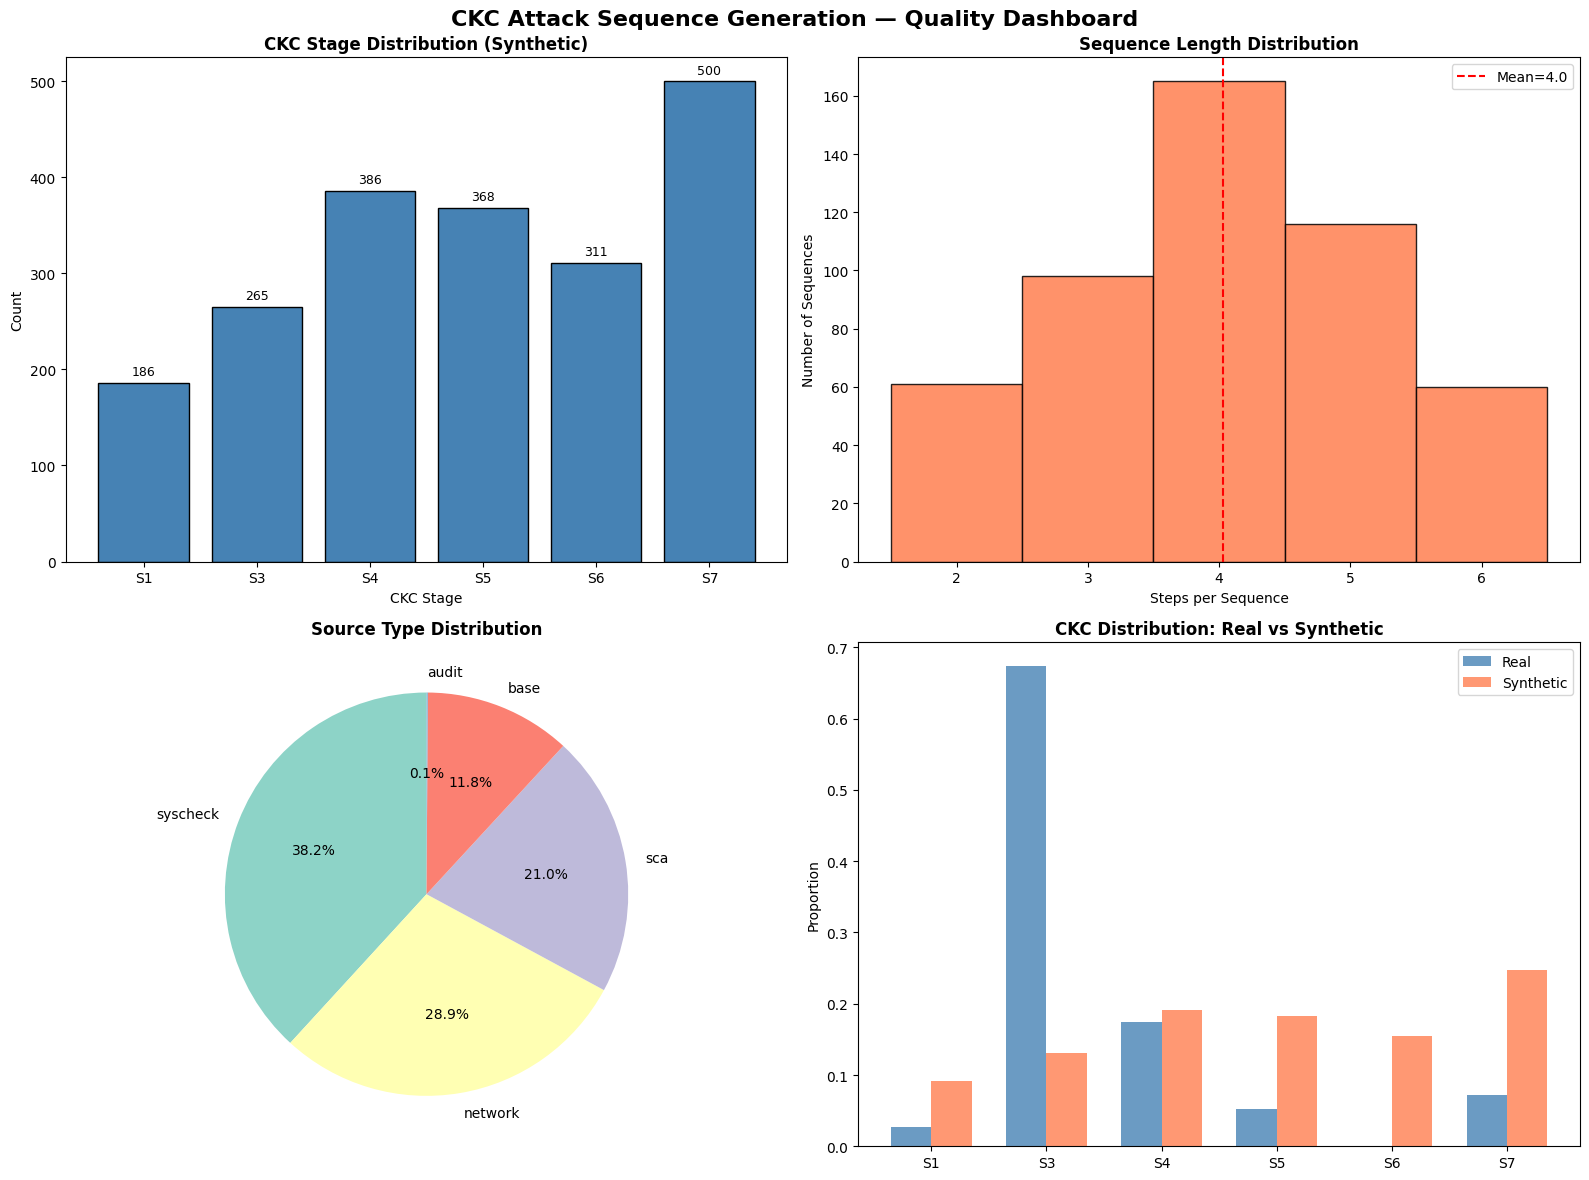

   ✅ Dashboard saved: D:\PFE_CKC\quality_dashboard.png


In [16]:
# ============================================================================
# 📊 VISUALIZATIONS
# ============================================================================

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.max_open_warning'] = 0

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('CKC Attack Sequence Generation — Quality Dashboard', fontsize=16, fontweight='bold')

# ── 1. CKC Stage Distribution (Synthetic) ──
ax = axes[0, 0]
if 'ckc_stage' in final_df.columns:
    stage_counts = final_df['ckc_stage'].value_counts().sort_index()
    bars = ax.bar(stage_counts.index, stage_counts.values, color='steelblue', edgecolor='black')
    ax.set_title('CKC Stage Distribution (Synthetic)', fontweight='bold')
    ax.set_xlabel('CKC Stage')
    ax.set_ylabel('Count')
    for bar, val in zip(bars, stage_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(val), ha='center', va='bottom', fontsize=9)

# ── 2. Sequence Length Distribution ──
ax = axes[0, 1]
seq_lens = final_df.groupby('sequence_id').size()
ax.hist(seq_lens, bins=range(seq_lens.min(), seq_lens.max() + 2), color='coral',
        edgecolor='black', alpha=0.85, align='left')
ax.set_title('Sequence Length Distribution', fontweight='bold')
ax.set_xlabel('Steps per Sequence')
ax.set_ylabel('Number of Sequences')
ax.axvline(seq_lens.mean(), color='red', linestyle='--', label=f'Mean={seq_lens.mean():.1f}')
ax.legend()

# ── 3. Source Type Distribution ──
ax = axes[1, 0]
if 'source_type' in final_df.columns:
    src_counts = final_df['source_type'].value_counts()
    ax.pie(src_counts.values, labels=src_counts.index, autopct='%1.1f%%',
           colors=plt.cm.Set3.colors[:len(src_counts)], startangle=90)
    ax.set_title('Source Type Distribution', fontweight='bold')

# ── 4. CKC Stage Comparison: Real vs Synthetic ──
ax = axes[1, 1]
if 'ckc_stage' in final_df.columns and 'cyber_kill_chain_summary' in train_df.columns:
    real_ckc = train_df['cyber_kill_chain_summary'].value_counts(normalize=True).sort_index()
    synth_ckc = final_df['ckc_stage'].value_counts(normalize=True).sort_index()
    all_stages_plot = sorted(set(real_ckc.index) | set(synth_ckc.index))
    x_pos = np.arange(len(all_stages_plot))
    w = 0.35
    ax.bar(x_pos - w/2, [real_ckc.get(s, 0) for s in all_stages_plot], w,
           label='Real', color='steelblue', alpha=0.8)
    ax.bar(x_pos + w/2, [synth_ckc.get(s, 0) for s in all_stages_plot], w,
           label='Synthetic', color='coral', alpha=0.8)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(all_stages_plot)
    ax.set_title('CKC Distribution: Real vs Synthetic', fontweight='bold')
    ax.set_ylabel('Proportion')
    ax.legend()

plt.tight_layout()
plt.savefig(save_dir / 'quality_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"   ✅ Dashboard saved: {save_dir / 'quality_dashboard.png'}")

🔵 Computing t-SNE (Real vs Synthetic)...


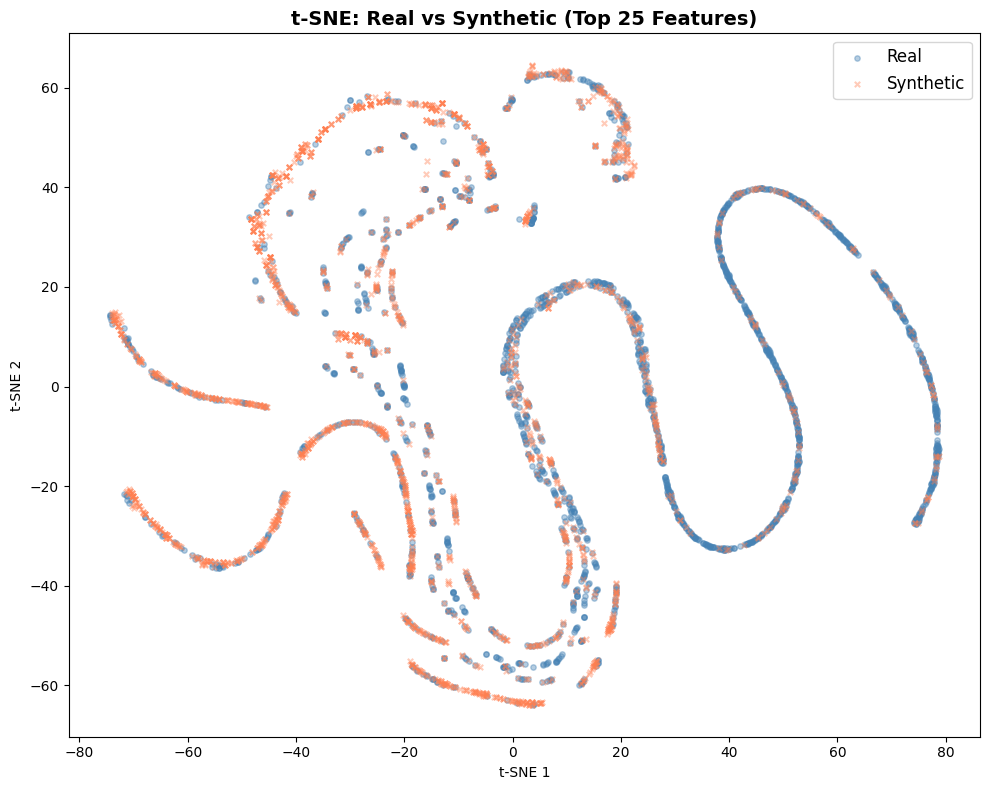

   ✅ t-SNE saved: D:\PFE_CKC\tsne_real_vs_synthetic.png


In [17]:
# ============================================================================
# 📊 t-SNE: Real vs Synthetic Embedding Space
# ============================================================================

from sklearn.manifold import TSNE

print("🔵 Computing t-SNE (Real vs Synthetic)...")

common_num = [f for f in TOP_25_COLUMNS if f in final_df.columns and f in train_df.columns]

if len(common_num) >= 3:
    # Sample for speed
    n_sample = min(3000, len(train_df), len(final_df))
    real_sample = train_df[common_num].fillna(0).sample(n_sample, random_state=42)
    synth_sample = final_df[common_num].fillna(0).sample(n_sample, random_state=42)

    combined = pd.concat([real_sample, synth_sample], ignore_index=True).values
    labels = ['Real'] * n_sample + ['Synthetic'] * n_sample

    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
    coords = tsne.fit_transform(combined)

    fig, ax = plt.subplots(figsize=(10, 8))
    for label, color, marker in [('Real', 'steelblue', 'o'), ('Synthetic', 'coral', 'x')]:
        mask = np.array(labels) == label
        ax.scatter(coords[mask, 0], coords[mask, 1], c=color, label=label,
                   alpha=0.4, s=15, marker=marker)
    ax.set_title('t-SNE: Real vs Synthetic (Top 25 Features)', fontsize=14, fontweight='bold')
    ax.legend(fontsize=12)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    plt.tight_layout()
    plt.savefig(save_dir / 'tsne_real_vs_synthetic.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"   ✅ t-SNE saved: {save_dir / 'tsne_real_vs_synthetic.png'}")
else:
    print("   ⚠️ Not enough common features for t-SNE")

## 🔎 Sample Attack Sequences

In [18]:
# ============================================================================
# 🔎 DISPLAY SAMPLE ATTACK SEQUENCES (with decoded text)
# ============================================================================

print("=" * 70)
print("🔎 SAMPLE ATTACK SEQUENCES")
print("=" * 70)

# Show 5 diverse sequences (different lengths)
sample_seqs = seq_summary.drop_duplicates(subset='n_steps').head(5)

display_cols = ['step_idx', 'ckc_stage', 'mitre_tactic', 'mitre_id', 'source_type']
if 'command' in final_df.columns:
    display_cols.append('command')
if 'rule_description' in final_df.columns:
    display_cols.append('rule_description')

for _, row in sample_seqs.iterrows():
    seq_id = row['sequence_id']
    seq_data = final_df[final_df['sequence_id'] == seq_id]
    n_steps = len(seq_data)
    stages = ' → '.join(seq_data['ckc_stage'].tolist())

    print(f"\n{'─' * 60}")
    print(f"🔗 Sequence {seq_id}  |  {n_steps} steps  |  {stages}")
    print(f"{'─' * 60}")

    avail_cols = [c for c in display_cols if c in seq_data.columns]
    for _, step in seq_data.iterrows():
        step_num = int(step.get('step_idx', 0))
        ckc = step.get('ckc_stage', '?')
        tactic = step.get('mitre_tactic', '?')
        mid = step.get('mitre_id', '?')
        src = step.get('source_type', '?')
        cmd = str(step.get('command', ''))[:80] if 'command' in step.index else ''
        desc = str(step.get('rule_description', ''))[:80] if 'rule_description' in step.index else ''

        print(f"  Step {step_num}: [{ckc}] {tactic} ({mid}) — {src}")
        if cmd and cmd not in ['', 'nan', 'MISSING', 'None']:
            print(f"          CMD: {cmd}")
        if desc and desc not in ['', 'nan', 'None']:
            print(f"          DESC: {desc}")

print(f"\n{'=' * 70}")
print(f"🎯 GENERATION COMPLETE!")
print(f"   📁 All outputs: {save_dir}")
print(f"   📊 Sequences: {n_sequences:,} | Rows: {len(final_df):,}")
print(f"   ✅ All sequences end with S7: {metadata.get('all_sequences_end_with_S7', 'N/A')}")
print(f"{'=' * 70}")

🔎 SAMPLE ATTACK SEQUENCES

────────────────────────────────────────────────────────────
🔗 Sequence 0  |  5 steps  |  S3 → S4 → S5 → S6 → S7
────────────────────────────────────────────────────────────
  Step 0: [S3] ["TA0001"] (["T1190"]) — network
          DESC: A web attack returned code 200 (success).
  Step 1: [S4] ["TA0002"] (["T1059.007"]) — network
          DESC: XSS (Cross Site Scripting) attempt.
  Step 2: [S5] ["TA0005","TA0040"] (["T1070.004","T1485"]) — syscheck
          DESC: File deleted.
  Step 3: [S6] ["TA0008"] (["T1040","T1203","T1543","T1543.002"]) — sca
          CMD: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0
          DESC: CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: Ensure rsh client is not installed.
  Step 4: [S7] ["TA0040"] (["T1565.001"]) — syscheck
          DESC: Integrity checksum changed.

────────────────────────────────────────────────────────────
🔗 Sequence 1  |  4 steps  |  S3 → S4 → S5 → S7
───────────────────────────────────────────────────────

In [21]:
# ============================================================================
# REVERSE MAP: Features -> Original Dataset Columns (No Embeddings)
# ============================================================================

import secrets

print("=" * 70)
print("FEATURES -> ORIGINAL DATASET COLUMNS")
print("=" * 70)

# Start with metadata
reverse_df = final_df[['sequence_id', 'step_idx', 'ckc_stage',
                        'mitre_tactic', 'mitre_id', 'source_type']].copy()

# Helper: safely get numeric series from final_df
def safe_col(col_name):
    if col_name in final_df.columns:
        return pd.to_numeric(final_df[col_name], errors='coerce').fillna(0)
    return pd.Series(0, index=final_df.index)

# 1. _source.decoder.name  (from decoder_* flags)
decoder_map = {
    'decoder_auditd': 'auditd',
    'decoder_web-accesslog': 'web-accesslog',
    'decoder_dpkg-decoder': 'dpkg-decoder',
    'decoder_syscheck_deleted': 'syscheck_deleted',
    'decoder_syscheck_integrity_changed': 'syscheck_integrity_changed',
}
reverse_df['_source.decoder.name'] = np.nan
for feat, name in decoder_map.items():
    mask = safe_col(feat) >= 0.5
    reverse_df.loc[mask, '_source.decoder.name'] = name

# 2. _source.rule.firedtimes
reverse_df['_source.rule.firedtimes'] = safe_col('firedtimes').clip(lower=0).round().astype(int)

# 3. _source.location  (from location_* flags)
location_map = {
    'location__var_log_audit_audit.log': '/var/log/audit/audit.log',
    'location__var_log_apache2_access.log': '/var/log/apache2/access.log',
    'location__var_log_auth.log': '/var/log/auth.log',
    'location_syscheck': 'syscheck',
}
reverse_df['_source.location'] = np.nan
for feat, loc in location_map.items():
    mask = safe_col(feat) >= 0.5
    reverse_df.loc[mask, '_source.location'] = loc

# 4. _source.data.srcip  (from srcip_is_private)
real_ips = raw_data['_source.data.srcip'].dropna().unique()
private_ips = [ip for ip in real_ips
               if str(ip).startswith(('10.','192.168.','172.16.','172.17.',
                                      '172.18.','172.19.','172.20.','172.21.',
                                      '172.22.','172.23.','172.24.','172.25.',
                                      '172.26.','172.27.','172.28.','172.29.',
                                      '172.30.','172.31.'))]
if not private_ips:
    private_ips = ['10.0.0.1', '192.168.1.1']

ip_mask = safe_col('srcip_is_private') >= 0.5
reverse_df['_source.data.srcip'] = np.nan
reverse_df.loc[ip_mask, '_source.data.srcip'] = [
    np.random.choice(private_ips) for _ in range(ip_mask.sum())]

# 5. _source.syscheck.path  (from path features)
real_paths = raw_data['_source.syscheck.path'].dropna().astype(str).unique()
_sensitive_dirs = ['/etc', '/root', '/var/log', '/boot', '/usr/sbin']
_temp_dirs      = ['/tmp', '/temp']
_sens_pool = [p for p in real_paths if any(d in p for d in _sensitive_dirs)]
_temp_pool = [p for p in real_paths if any(d in p for d in _temp_dirs)]
_other_pool= [p for p in real_paths if p not in _sens_pool and p not in _temp_pool]

path_missing = safe_col('path_is_missing')
path_depth   = safe_col('path_depth')
path_temp    = safe_col('path_is_temp')
path_sens    = safe_col('path_is_sensitive')

def pick_path(i):
    if path_missing.iloc[i] >= 0.5:
        return np.nan
    depth = int(max(path_depth.iloc[i], 1))
    if path_temp.iloc[i] >= 0.5:
        pool = [p for p in _temp_pool if p.count('/') == depth] or _temp_pool
    elif path_sens.iloc[i] >= 0.5:
        pool = [p for p in _sens_pool if p.count('/') == depth] or _sens_pool
    else:
        pool = [p for p in _other_pool if p.count('/') == depth] or _other_pool or list(real_paths)
    return np.random.choice(pool) if pool else np.nan

reverse_df['_source.syscheck.path'] = [pick_path(i) for i in range(len(final_df))]

# 6. _source.syscheck.md5_after  (from has_md5 -> random MD5 hash)
md5_mask = safe_col('has_md5') >= 0.5
reverse_df['_source.syscheck.md5_after'] = np.nan
reverse_df.loc[md5_mask, '_source.syscheck.md5_after'] = [
    secrets.token_hex(16) for _ in range(md5_mask.sum())]

# 7. _source.syscheck.sha256_after  (from has_sha256 -> random SHA256 hash)
sha_mask = safe_col('has_sha256') >= 0.5
reverse_df['_source.syscheck.sha256_after'] = np.nan
reverse_df.loc[sha_mask, '_source.syscheck.sha256_after'] = [
    secrets.token_hex(32) for _ in range(sha_mask.sum())]

# 8. _source.syscheck.event  (from syscheck_added / _deleted / _modified)
event_map = {
    'syscheck_added': 'added',
    'syscheck_deleted': 'deleted',
    'syscheck_modified': 'modified',
}
reverse_df['_source.syscheck.event'] = np.nan
for feat, ev in event_map.items():
    mask = safe_col(feat) >= 0.5
    reverse_df.loc[mask, '_source.syscheck.event'] = ev

# 9. _source.data.command  (already decoded)
if 'command' in final_df.columns:
    reverse_df['_source.data.command'] = final_df['command']

# 10. _source.rule.description  (already decoded from log embedding)
if 'rule_description' in final_df.columns:
    reverse_df['_source.rule.description'] = final_df['rule_description']

# Summary & Save
orig_cols = [c for c in reverse_df.columns if c.startswith('_source.')]
print(f"\nREVERSE-MAPPED DATASET:")
print(f"   Shape: {reverse_df.shape[0]:,} rows x {reverse_df.shape[1]} cols")
print(f"   Metadata: sequence_id, step_idx, ckc_stage, mitre_tactic, mitre_id, source_type")
print(f"   Original columns restored ({len(orig_cols)}):")
for c in orig_cols:
    nn = reverse_df[c].notna().sum()
    print(f"     {c}: {nn}/{len(reverse_df)} ({nn/len(reverse_df)*100:.1f}%)")

save_dir = Path(OUTPUT_DIR)
reverse_df.to_csv(save_dir / 'ckc_sequences_original_columns.csv', index=False)
reverse_df.to_excel(save_dir / 'ckc_sequences_original_columns.xlsx', index=False, engine='openpyxl')
print(f"\nSaved to {OUTPUT_DIR}/ckc_sequences_original_columns.csv/.xlsx")

print(f"\nSample (first 8 rows):")
display(reverse_df.head(8))

FEATURES -> ORIGINAL DATASET COLUMNS

REVERSE-MAPPED DATASET:
   Shape: 2,016 rows x 16 cols
   Metadata: sequence_id, step_idx, ckc_stage, mitre_tactic, mitre_id, source_type
   Original columns restored (10):
     _source.decoder.name: 1330/2016 (66.0%)
     _source.rule.firedtimes: 2016/2016 (100.0%)
     _source.location: 1567/2016 (77.7%)
     _source.data.srcip: 583/2016 (28.9%)
     _source.syscheck.path: 2016/2016 (100.0%)
     _source.syscheck.md5_after: 770/2016 (38.2%)
     _source.syscheck.sha256_after: 770/2016 (38.2%)
     _source.syscheck.event: 770/2016 (38.2%)
     _source.data.command: 2016/2016 (100.0%)
     _source.rule.description: 2016/2016 (100.0%)

Saved to D:\PFE_CKC/ckc_sequences_original_columns.csv/.xlsx

Sample (first 8 rows):


,sequence_id,step_idx,ckc_stage,mitre_tactic,mitre_id,source_type,_source.decoder.name,_source.rule.firedtimes,_source.location,_source.data.srcip,_source.syscheck.path,_source.syscheck.md5_after,_source.syscheck.sha256_after,_source.syscheck.event,_source.data.command,_source.rule.description
860,0,0,S3,"[""TA0001""]","[""T1190""]",network,web-accesslog,1100,/var/log/apache2/access.log,192.168.217.1,/usr/bin/piconv,NaN,NaN,NaN,,A web attack returned code 200 (success).
5390,0,1,S4,"[""TA0002""]","[""T1059.007""]",network,web-accesslog,199,/var/log/apache2/access.log,192.168.204.1,/usr/bin/vim.tiny,NaN,NaN,NaN,,XSS (Cross Site Scripting) attempt.
5226,0,2,S5,"[""TA0005"",""TA0040""]","[""T1070.004"",""T1485""]",syscheck,syscheck_deleted,152,syscheck,NaN,/tmp/go-build2314020258/b117/curve25519_amd64.o,ed9eca34e118ea06fd92052f6036b38c,ca7ac4512b9064f73e544cfa670b681d5b84043e52d360...,deleted,,File deleted.
71,0,3,S6,"[""TA0008""]","[""T1040"",""T1203"",""T1543"",""T1543.002""]",sca,NaN,29,NaN,NaN,/usr/bin/avahi-publish-address,NaN,NaN,NaN,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: E...
5734,0,4,S7,"[""TA0040""]","[""T1565.001""]",syscheck,syscheck_integrity_changed,17,syscheck,NaN,/tmp/apt.data.iCaXH6,474276c80fc0aaf5ab9905340fdef7ef,24ab6187309be22960318b9f034ea193a78d79d5fc13c7...,modified,,Integrity checksum changed.
4426,1,0,S3,"[""TA0001""]","[""T1190""]",network,web-accesslog,961,/var/log/apache2/access.log,192.168.204.1,/usr/bin/pdftotext,NaN,NaN,NaN,,A web attack returned code 200 (success).
5578,1,1,S4,"[""TA0002""]","[""T1059.007""]",network,web-accesslog,159,/var/log/apache2/access.log,192.168.217.1,/usr/bin/pfbtopfa,NaN,NaN,NaN,,XSS (Cross Site Scripting) attempt.
6231,1,2,S5,"[""TA0003""]","[""T1078"",""T1078.001"",""T1078.003""]",sca,NaN,71,NaN,NaN,/usr/bin/ps2epsi,NaN,NaN,NaN,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: E...
